Melinda Venta Lydia Siburian
(23031554124)

# SOAL UTS GRAF SAINS DATA

## **2.1 Wrangling dan EDA**

Menyiapkan library untuk membaca data, mengakses Neo4j melalui Python API, membangun matriks sparse, dan membuat visualisasi NetworkX.

In [3]:
%pip install pandas numpy scipy scikit-learn matplotlib networkx neo4j

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix, save_npz
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase
from getpass import getpass

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

OUTPUT_DIR = "/content/hasil_analisis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Folder output:", OUTPUT_DIR)

Folder output: /content/hasil_analisis


### no.1 dan 2 : Split Dataset berdasarkan timestamp

In [5]:
# GANTI sesuai lokasi events.csv milikmu
DATA_PATH = r"C:\Users\Melinda Siburian\OneDrive\Documents\uts_gsd\data\archive (4)\events.csv"

P1_START = "2015-05-16"
P1_END   = "2015-08-04"

P2_START = "2015-08-05"
P2_END   = "2015-08-25"

# Batas akhir eksklusif: awal hari setelah tanggal akhir
P1_START_TS = pd.Timestamp(P1_START, tz="UTC")
P1_END_EXCLUSIVE = pd.Timestamp(P1_END, tz="UTC") + pd.Timedelta(days=1)

P2_START_TS = pd.Timestamp(P2_START, tz="UTC")
P2_END_EXCLUSIVE = pd.Timestamp(P2_END, tz="UTC") + pd.Timedelta(days=1)

print("P1:", P1_START_TS, "sampai sebelum", P1_END_EXCLUSIVE)
print("P2:", P2_START_TS, "sampai sebelum", P2_END_EXCLUSIVE)

assert os.path.exists(DATA_PATH), (
    f"File tidak ditemukan: {DATA_PATH}. "
    "Silakan ubah DATA_PATH sesuai lokasi events.csv."
)

P1: 2015-05-16 00:00:00+00:00 sampai sebelum 2015-08-05 00:00:00+00:00
P2: 2015-08-05 00:00:00+00:00 sampai sebelum 2015-08-26 00:00:00+00:00


**Membaca dan memeriksa dataset**

memeriksa nama kolom, tipe data, jumlah baris, dan distribusi event.


In [6]:
df = pd.read_csv(DATA_PATH)

required_columns = {
    "timestamp", "visitorid", "event", "itemid"
}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

# Timestamp RetailRocket merupakan Unix time dalam milidetik
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.dropna(
    subset=["timestamp", "visitorid", "event", "itemid"]
).copy()

df["timestamp"] = df["timestamp"].astype("int64")

# Identitas diseragamkan sebagai string agar aman saat diimpor ke Neo4j
df["visitorid"] = df["visitorid"].astype(str)
df["itemid"] = df["itemid"].astype(str)
df["event"] = df["event"].astype(str)

df["event_datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

print("Jumlah interaksi setelah membersihkan kolom wajib:", len(df))
print("\nContoh data:")
display(df.head())

print("\nDistribusi event:")
display(df["event"].value_counts().rename_axis("event").to_frame("jumlah"))

Jumlah interaksi setelah membersihkan kolom wajib: 2756101

Contoh data:


,timestamp,visitorid,event,itemid,transactionid,event_datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00



Distribusi event:


,jumlah
event,
view,2664312
addtocart,69332
transaction,22457


**Pembagian P1 dan P2 dan disimpan di CSV**


In [7]:
mask_p1 = (
    (df["event_datetime"] >= P1_START_TS) &
    (df["event_datetime"] < P1_END_EXCLUSIVE)
)

mask_p2 = (
    (df["event_datetime"] >= P2_START_TS) &
    (df["event_datetime"] < P2_END_EXCLUSIVE)
)

p1 = df.loc[mask_p1].copy()
p2 = df.loc[mask_p2].copy()

p1["period"] = "P1"
p2["period"] = "P2"

# Simpan kolom inti; timestamp asli tetap dipertahankan
CSV_COLUMNS = [
    "timestamp", "visitorid", "event", "itemid", "period"
]

p1_csv = os.path.join(OUTPUT_DIR, "retailrocket_P1_training.csv")
p2_csv = os.path.join(OUTPUT_DIR, "retailrocket_P2_testing.csv")
all_csv = os.path.join(OUTPUT_DIR, "retailrocket_P1_P2_filtered.csv")

p1[CSV_COLUMNS].to_csv(p1_csv, index=False)
p2[CSV_COLUMNS].to_csv(p2_csv, index=False)
pd.concat([p1[CSV_COLUMNS], p2[CSV_COLUMNS]], ignore_index=True).to_csv(
    all_csv, index=False
)

print("Jumlah interaksi P1:", len(p1))
print("Jumlah interaksi P2:", len(p2))
print("CSV P1:", p1_csv)
print("CSV P2:", p2_csv)
print("CSV gabungan:", all_csv)

assert len(p1) > 0, "P1 kosong. Periksa timestamp dan periode."
assert len(p2) > 0, "P2 kosong. Periksa timestamp dan periode."

Jumlah interaksi P1: 1716085
Jumlah interaksi P2: 372163
CSV P1: /content/hasil_analisis\retailrocket_P1_training.csv
CSV P2: /content/hasil_analisis\retailrocket_P2_testing.csv
CSV gabungan: /content/hasil_analisis\retailrocket_P1_P2_filtered.csv


**Komposisi periode dan event setelah filter**

In [8]:
print("Interaksi per periode:")
display(
    pd.concat([p1, p2])
    .groupby("period")
    .agg(
        jumlah_interaksi=("itemid", "size"),
        jumlah_user=("visitorid", "nunique"),
        jumlah_item=("itemid", "nunique")
    )
)

print("\nEvent per periode:")
display(
    pd.concat([p1, p2])
    .groupby(["period", "event"])
    .size()
    .unstack(fill_value=0)
)

Interaksi per periode:


,jumlah_interaksi,jumlah_user,jumlah_item
period,,,
P1,1716085,879515,191638
P2,372163,212596,92531



Event per periode:


event,addtocart,transaction,view
period,,,
P1,42210,13942,1659933
P2,9891,3076,359196


**JAWABAN NO.1**
1. Data sudah difilter berdasarkan periode waktu yang sudah ditentukan.
- P1: 2015-05-16 00:00:00+00:00 sampai sebelum 2015-08-05 00:00:00+00:00
- P2: 2015-08-05 00:00:00+00:00 sampai sebelum 2015-08-26 00:00:00+00:00

2. P1 dan P2 sudah tersimpan di csv 
- CSV P1: /content/hasil_analisis\retailrocket_P1_training.csv
- CSV P2: /content/hasil_analisis\retailrocket_P2_testing.csv

**Menganalisis karakteristik data interaksi pada periode P1 dan P2 sebelum membangun sistem rekomendasi.**

1. User unik adalah jumlah pengunjung berbeda yang melakukan interaksi pada suatu periode, sehingga satu pengunjung yang melakukan banyak aktivitas tetap dihitung sebagai satu user. 
2. Item unik adalah jumlah produk berbeda yang memperoleh interaksi, sehingga satu produk yang dilihat berkali-kali tetap dihitung sebagai satu item. 

Dihitung jumlah user dan item yang muncul pada kedua periode menggunakan operasi irisan himpunan (&). Informasi ini penting untuk mengetahui berapa banyak user yang dapat digunakan sebagai user acuan dan berapa banyak item yang berpotensi dievaluasi.

In [9]:

# ============================================================
# 1. RINGKASAN INTERAKSI, USER UNIK, DAN ITEM UNIK PER PERIODE
# ============================================================

data_all = pd.concat([p1, p2], ignore_index=True)

print("Interaksi, User Unik, dan Item Unik per Periode:")

display(
    data_all.groupby("period")
    .agg(
        jumlah_interaksi=("itemid", "size"),
        jumlah_user_unik=("visitorid", "nunique"),
        jumlah_item_unik=("itemid", "nunique")
    )
    .reset_index()
)

# ============================================================
# 2. DISTRIBUSI EVENT PER PERIODE
# ============================================================

print("\nDistribusi Event per Periode:")

display(
    data_all.groupby(["period", "event"])
    .size()
    .unstack(fill_value=0)
)

# ============================================================
# 3. USER UNIK DAN ITEM UNIK PADA MASING-MASING PERIODE
# ============================================================

users_p1 = set(p1["visitorid"].unique())
users_p2 = set(p2["visitorid"].unique())

items_p1 = set(p1["itemid"].unique())
items_p2 = set(p2["itemid"].unique())

print("\nPerbandingan User dan Item Unik:")

print(f"User unik P1                  : {len(users_p1):,}")
print(f"User unik P2                  : {len(users_p2):,}")
print(f"User yang muncul di P1 dan P2 : {len(users_p1 & users_p2):,}")

print(f"\nItem unik P1                  : {len(items_p1):,}")
print(f"Item unik P2                  : {len(items_p2):,}")
print(f"Item yang muncul di P1 dan P2 : {len(items_p1 & items_p2):,}")


Interaksi, User Unik, dan Item Unik per Periode:


,period,jumlah_interaksi,jumlah_user_unik,jumlah_item_unik
0,P1,1716085,879515,191638
1,P2,372163,212596,92531



Distribusi Event per Periode:


event,addtocart,transaction,view
period,,,
P1,42210,13942,1659933
P2,9891,3076,359196



Perbandingan User dan Item Unik:
User unik P1                  : 879,515
User unik P2                  : 212,596
User yang muncul di P1 dan P2 : 16,951

Item unik P1                  : 191,638
Item unik P2                  : 92,531
Item yang muncul di P1 dan P2 : 75,139


Hasil diatas menunjukkan bahwa P1 memiliki 879.515 user unik dan 191.638 item unik, sedangkan P2 memiliki 212.596 user unik dan 92.531 item unik. Dari kedua periode tersebut, hanya 16.951 user yang muncul pada P1 dan P2, yang berarti sebagian besar user pada P2 tidak memiliki riwayat interaksi pada P1. Sementara itu, terdapat 75.139 item yang muncul pada kedua periode, sehingga sebagian besar item di P2 sudah pernah muncul pada P1.

**Konfigurasi koneksi Neo4j**

In [10]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

# Gunakan "neo4j" jika memakai database default.
DATABASE = "neo4j"

driver = None

try:
    driver = GraphDatabase.driver(
        URI,
        auth=(USERNAME, PASSWORD)
    )

    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")

    with driver.session(database=DATABASE) as session:
        result = session.run(
            "RETURN 'Koneksi berhasil' AS status"
        )
        record = result.single()
        print(record["status"])

except Exception as e:
    print("Koneksi gagal:", e)

finally:
    if driver is not None:
        driver.close()


Koneksi ke Neo4j berhasil!
Koneksi berhasil


In [11]:

from neo4j import GraphDatabase
from getpass import getpass

URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
DATABASE = "neo4j"

PASSWORD = getpass("Masukkan password Neo4j: ")

# Buat driver baru
driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

# Pastikan koneksi aktif
driver.verify_connectivity()

print("Koneksi Neo4j berhasil dan driver aktif!")


Koneksi Neo4j berhasil dan driver aktif!


**Membuat skema graf dan constraint**

membuat constraint (batasan integritas data) pada Neo4j agar setiap node Visitor memiliki nilai visitorId yang unik dan setiap node Item memiliki nilai itemId yang unik.

Penjelasan Cypher yang digunakan:
- **CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS**: membuat constraint bernama visitor_id_unique
- **FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE**: memastikan setiap node berlabel Visitor memiliki nilai visitorId yang unik.
- **CREATE CONSTRAINT item_id_unique IF NOT EXISTS**: membuat constraint bernama item_id_unique jika belum tersedia.
- **FOR (i:Item) REQUIRE i.itemId IS UNIQUE**: memastikan setiap node berlabel Item memiliki nilai itemId yang unik.
- **session.run(query).consume()**: menjalankan setiap perintah Cypher dan memastikan hasil eksekusinya dikonsumsi oleh driver.

In [15]:
SCHEMA_QUERIES = [
    """
    CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
    FOR (v:Visitor)
    REQUIRE v.visitorId IS UNIQUE
    """,
    """
    CREATE CONSTRAINT item_id_unique IF NOT EXISTS
    FOR (i:Item)
    REQUIRE i.itemId IS UNIQUE
    """
]

with driver.session() as session:
    for query in SCHEMA_QUERIES:
        session.run(query).consume()

print("Constraint Visitor dan Item berhasil disiapkan.")

Constraint Visitor dan Item berhasil disiapkan.


**Mengimpor data P1 dan P2 ke Neo4j**

Keterangan sintaks Cypher:
- **UNWIND $rows AS row**: memproses setiap baris dari parameter rows sebagai variabel row.
- **MERGE (v:Visitor {visitorId: row.visitorid})**: membuat node Visitor jika belum ada, atau menggunakan node yang sudah ada berdasarkan visitorId.
- **MERGE (i:Item {itemId: row.itemid})**: membuat atau menggunakan kembali node Item berdasarkan itemId.
- **CALL apoc.create.relationship(...)**: membuat relasi secara dinamis sesuai jenis event pada data.
- **toUpper(row.event)**: mengubah nama event menjadi huruf kapital, misalnya view menjadi VIEW.
- **{timestamp: row.timestamp, period: row.period}**: menyimpan properti waktu interaksi dan periode pada relasi.
- **YIELD rel**: mengambil relasi yang berhasil dibuat oleh prosedur APOC.
- **RETURN count(rel) AS imported**: menghitung jumlah relasi yang dibuat dalam satu eksekusi batch.

In [17]:

# ============================================================
# 1. QUERY IMPORT DENGAN RELASI SESUAI EVENT DATASET
# ============================================================

IMPORT_QUERY = """
UNWIND $rows AS row

MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})

CALL apoc.create.relationship(
    v,
    toUpper(row.event),
    {
        timestamp: row.timestamp,
        period: row.period
    },
    i
) YIELD rel

RETURN count(rel) AS imported
"""


# ============================================================
# 2. FUNGSI IMPORT DATA KE NEO4J
# ============================================================

def import_interactions_to_neo4j(dataframe, batch_size=5000):

    records = dataframe[
        ["timestamp", "visitorid", "event", "itemid", "period"]
    ].to_dict("records")

    total = len(records)

    with driver.session() as session:
        for start in range(0, total, batch_size):
            batch = records[start:start + batch_size]

            result = session.run(
                IMPORT_QUERY,
                rows=batch
            )
            imported = result.single()["imported"]

            print(
                f"Diimpor {min(start + len(batch), total):,}"
                f" / {total:,} baris; batch ini: {imported:,}"
            )


# ============================================================
# 3. GABUNGKAN DAN IMPOR DATA P1 + P2
# ============================================================

filtered_data = pd.concat([p1, p2], ignore_index=True)

import_interactions_to_neo4j(
    filtered_data,
    batch_size=5000
)


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description="warn: feature deprecated with replacement. apoc.create.relationship is deprecated. It is replaced by Cypher's dynamic types: `CREATE (from)-[n:$(relType)]->(to) SET n = props`.", position=<SummaryInputPosition line=7, column=1, offset=104>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 104, 'line': 7, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nUNWIND $rows AS row\n\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\n\nCALL apoc.create.relationship(\n    v,\n    toUpper(row.event),\n    {\n        timestamp: row.timestamp,\n        period: row.period\n    },\n    i\n) YIELD rel\n

Diimpor 5,000 / 2,088,248 baris; batch ini: 5,000


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description="warn: feature deprecated with replacement. apoc.create.relationship is deprecated. It is replaced by Cypher's dynamic types: `CREATE (from)-[n:$(relType)]->(to) SET n = props`.", position=<SummaryInputPosition line=7, column=1, offset=104>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 104, 'line': 7, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nUNWIND $rows AS row\n\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\n\nCALL apoc.create.relationship(\n    v,\n    toUpper(row.event),\n    {\n        timestamp: row.timestamp,\n        period: row.period\n    },\n    i\n) YIELD rel\n

Diimpor 10,000 / 2,088,248 baris; batch ini: 5,000


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description="warn: feature deprecated with replacement. apoc.create.relationship is deprecated. It is replaced by Cypher's dynamic types: `CREATE (from)-[n:$(relType)]->(to) SET n = props`.", position=<SummaryInputPosition line=7, column=1, offset=104>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 104, 'line': 7, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nUNWIND $rows AS row\n\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\n\nCALL apoc.create.relationship(\n    v,\n    toUpper(row.event),\n    {\n        timestamp: row.timestamp,\n        period: row.period\n    },\n    i\n) YIELD rel\n

...

Diimpor 2,075,000 / 2,088,248 baris; batch ini: 5,000


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description="warn: feature deprecated with replacement. apoc.create.relationship is deprecated. It is replaced by Cypher's dynamic types: `CREATE (from)-[n:$(relType)]->(to) SET n = props`.", position=<SummaryInputPosition line=7, column=1, offset=104>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 104, 'line': 7, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nUNWIND $rows AS row\n\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\n\nCALL apoc.create.relationship(\n    v,\n    toUpper(row.event),\n    {\n        timestamp: row.timestamp,\n        period: row.period\n    },\n    i\n) YIELD rel\n

Diimpor 2,080,000 / 2,088,248 baris; batch ini: 5,000


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description="warn: feature deprecated with replacement. apoc.create.relationship is deprecated. It is replaced by Cypher's dynamic types: `CREATE (from)-[n:$(relType)]->(to) SET n = props`.", position=<SummaryInputPosition line=7, column=1, offset=104>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 104, 'line': 7, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nUNWIND $rows AS row\n\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\n\nCALL apoc.create.relationship(\n    v,\n    toUpper(row.event),\n    {\n        timestamp: row.timestamp,\n        period: row.period\n    },\n    i\n) YIELD rel\n

Diimpor 2,085,000 / 2,088,248 baris; batch ini: 5,000
Diimpor 2,088,248 / 2,088,248 baris; batch ini: 3,248


### No. 3: Komposisi subgraph (Cypher + Python API)

**Menjalankan Cypher untuk mengetahui komposisi subgraph**


**Query untuk menghitung jumlah node berdasarkan label**

Penjelasan Cypher:
- MATCH (n) mengambil seluruh node dalam database.
- labels(n) memperoleh label dari setiap node.
- UNWIND mengubah daftar label menjadi baris terpisah.
- count(*) menghitung jumlah node untuk setiap label.
Karena query ini menghitung node di seluruh database, hasilnya mencakup node yang berinteraksi pada P1 maupun P2.

In [18]:
QUERY_NODE_COMPOSITION = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah_node
ORDER BY label
"""

with driver.session() as session:
    node_composition = pd.DataFrame(
        [record.data() for record in session.run(QUERY_NODE_COMPOSITION)]
    )

display(node_composition)

,label,jumlah_node
0,Item,209030
1,Visitor,1075160


**Query untuk komposisi subgraph P1**

Penjelasan Cypher:
- MATCH memilih relasi interaksi dari Visitor ke Item.
- {period: 'P1'} membatasi analisis pada relasi training.
- count(r) menghitung semua relasi interaksi, termasuk relasi berulang antara pasangan user-item.
- count(DISTINCT v) dan count(DISTINCT i) menghitung user dan item unik yang terlibat dalam P1.

In [19]:
QUERY_P1_COMPOSITION = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
  AND r.period = 'P1'
RETURN
    count(r) AS jumlah_relasi,
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(DISTINCT v) + count(DISTINCT i) AS jumlah_node_terlibat
"""

with driver.session() as session:
    p1_composition = session.run(
        QUERY_P1_COMPOSITION
    ).single().data()

display(pd.DataFrame([p1_composition]))

,jumlah_relasi,jumlah_visitor,jumlah_item,jumlah_node_terlibat
0,1716085,879515,191638,1071153


Terdapat 1.716.085 relasi interaksi, yang menunjukkan jumlah hubungan aktivitas pengunjung dengan produk, serta 879.515 visitor dan 191.638 item.

Sementara itu, jumlah node terlibat sebanyak 1.071.153 berarti jumlah pengunjung dan produk unik yang benar-benar memiliki hubungan interaksi dalam graph training. Sebagai contoh, pengunjung yang melihat suatu produk akan membentuk hubungan antara node visitor dan node item. Jika ada pengunjung atau produk yang tidak memiliki interaksi selama periode training, node tersebut tidak dihitung sebagai node yang terlibat. Jadi, jumlah node terlibat menunjukkan berapa banyak pengunjung dan produk yang benar-benar berpartisipasi dalam aktivitas pada graph training.

**Query untuk menghitung jenis event dalam subgraph P1**

In [20]:
QUERY_P1_EVENT_COMPOSITION = """
MATCH (:Visitor)-[r]->(:Item)
WHERE type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
  AND r.period = 'P1'
RETURN
    type(r) AS event,
    count(r) AS jumlah_interaksi
ORDER BY jumlah_interaksi DESC
"""

with driver.session() as session:
    event_composition = pd.DataFrame(
        [
            record.data()
            for record in session.run(QUERY_P1_EVENT_COMPOSITION)
        ]
    )

display(event_composition)

,event,jumlah_interaksi
0,VIEW,1659933
1,ADDTOCART,42210
2,TRANSACTION,13942


jumlah_relasi	jumlah_visitor	jumlah_item	jumlah_node_terlibat
0	1716085	879515	191638	1071153

**JAWABAN NO.3**. Subgraph yang dibentuk terdiri atas dua jenis node, yaitu Item sebanyak 209.030 node dan Visitor sebanyak 1.075.160 node, yang merepresentasikan produk dan pengunjung dalam dataset. 
Berdasarkan analisis komposisi menunjukkan bahwa graf Neo4j memiliki 1.716.085 relasi, yang menghubungkan 879.515 node Visitor dengan 191.638 node Item. Total keseluruhan node adalah 1.071.153, sehingga seluruh node yang tercatat terlibat dalam graf.
- Jumlah relasi (1.716.085): total hubungan interaksi antara pengunjung dan item, seperti VIEW, ADDTOCART, dan TRANSACTION.
- Jumlah node terlibat (1.071.153): total node unik yang terlibat dalam graf, yaitu gabungan node Visitor dan Item yang tercatat dalam hasil tersebut.

### No.4 : Membentuk VSM User dari P1


Pada VSM User, setiap baris mewakili satu Visitor, sedangkan setiap kolom mewakili satu Item. Nilai matriks adalah akumulasi bobot event untuk pasangan user-item. Karena satu user dapat melakukan beberapa jenis interaksi dengan item yang sama, bobotnya dijumlahkan.

VSM User disimpan dalam format sparse matrix CSR karena sebagian besar elemen matriks bernilai nol. Dengan ukuran (879.515 X 191.638), array padat bertipe float32 membutuhkan sekitar 625 GB memori, sedangkan CSR hanya menyimpan nilai nonzero beserta indeksnya. Oleh karena itu, CSR lebih hemat memori dan lebih sesuai untuk perhitungan cosine similarity pada dataset besar.

1. Dari analisis sebelumnya, dapat dilihat komposisi event "view" jauh lebih banyak dari pada "addtocart" dan "transaction". oleh karena itu, proses perhitungan vsm, similarity, dan rekomendasi seterusnya akan dibangun dari data dengan event "view" saja
2. Untuk setiap pasangan pengguna–item, hanya interaksi view paling awal yang dipertahankan. Dengan demikian, setiap pasangan pengguna–item memiliki bobot 1 dan tidak terhitung berulang kali.

In [80]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# ============================================================
# 1. FILTER DATA VIEW SAJA PADA P1
# ============================================================

vsm_data = p1.copy()

vsm_data["event"] = (
    vsm_data["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

vsm_data = vsm_data[
    vsm_data["event"] == "view"
].copy()

print("Jumlah event view sebelum deduplikasi:", len(vsm_data))

# ============================================================
# 2. PERTAHANKAN VIEW PALING AWAL PER PASANGAN USER-ITEM
# ============================================================

# Pastikan timestamp dapat diurutkan dengan benar.
# Sesuaikan nama kolom jika timestamp pada dataset berbeda.
vsm_data["timestamp"] = pd.to_numeric(
    vsm_data["timestamp"],
    errors="coerce"
)

# Urutkan berdasarkan waktu paling awal.
vsm_data = vsm_data.sort_values(
    "timestamp",
    ascending=True,
    na_position="last"
)

# Untuk setiap pasangan pengguna-item, pertahankan
# hanya satu view paling awal.
vsm_data = vsm_data.drop_duplicates(
    subset=["visitorid", "itemid"],
    keep="first"
).copy()

print("Jumlah event view setelah deduplikasi:", len(vsm_data))
print(
    "Jumlah pasangan user-item unik:",
    vsm_data[["visitorid", "itemid"]].drop_duplicates().shape[0]
)

# ============================================================
# 3. SETIAP INTERAKSI VIEW MEMILIKI BOBOT 1
# ============================================================

vsm_data["weight"] = 1.0

# ============================================================
# 4. BENTUK INDEKS USER DAN ITEM
# ============================================================

user_item_agg = (
    vsm_data.groupby(
        ["visitorid", "itemid"],
        as_index=False
    )["weight"]
    .sum()
)

user_ids = sorted(user_item_agg["visitorid"].unique())
item_ids = sorted(user_item_agg["itemid"].unique())

user_to_idx = {
    uid: idx for idx, uid in enumerate(user_ids)
}

item_to_idx = {
    iid: idx for idx, iid in enumerate(item_ids)
}

row_idx = (
    user_item_agg["visitorid"]
    .map(user_to_idx)
    .to_numpy()
)

col_idx = (
    user_item_agg["itemid"]
    .map(item_to_idx)
    .to_numpy()
)

values = user_item_agg["weight"].to_numpy(dtype=np.float32)

# ============================================================
# 5. BENTUK SPARSE USER VSM
# ============================================================

X_user = csr_matrix(
    (values, (row_idx, col_idx)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

# ============================================================
# 6. RINGKASAN VSM
# ============================================================

total_elements = X_user.shape[0] * X_user.shape[1]
sparsity = (
    1 - X_user.nnz / total_elements
    if total_elements > 0 else 0
)

print("\n========== VSM USER (VIEW ONLY) ==========")
print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Shape VSM User:", X_user.shape)
print("Jumlah nilai non-zero:", X_user.nnz)
print("Total elemen matriks:", total_elements)
print("Sparsity:", sparsity)
print("Nilai bobot unik:", np.unique(X_user.data))

Jumlah event view sebelum deduplikasi: 1659933
Jumlah event view setelah deduplikasi: 1327072
Jumlah pasangan user-item unik: 1327072

========== VSM USER (VIEW ONLY) ==========
Jumlah user: 877601
Jumlah item: 191463
Shape VSM User: (877601, 191463)
Jumlah nilai non-zero: 1327072
Total elemen matriks: 168028120263
Sparsity: 0.9999921020838779
Nilai bobot unik: [1.]


**Menyimpan VSM USER**

In [81]:
import os
import numpy as np
import pandas as pd
from scipy.sparse import save_npz

# ============================================================
# SIMPAN VSM USER (VIEW ONLY)
# ============================================================

OUTPUT_DIR = "vsm_user_view_p1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Simpan matriks VSM dalam format sparse
save_npz(
    os.path.join(OUTPUT_DIR, "vsm_user.npz"),
    X_user
)

# 2. Simpan urutan ID user sesuai indeks baris matriks
pd.DataFrame({
    "user_index": np.arange(len(user_ids)),
    "visitorid": user_ids
}).to_csv(
    os.path.join(OUTPUT_DIR, "user_ids.csv"),
    index=False
)

# 3. Simpan urutan ID item sesuai indeks kolom matriks
pd.DataFrame({
    "item_index": np.arange(len(item_ids)),
    "itemid": item_ids
}).to_csv(
    os.path.join(OUTPUT_DIR, "item_ids.csv"),
    index=False
)

# 4. Simpan informasi dimensi dan jumlah elemen
metadata = pd.DataFrame([{
    "jumlah_user": X_user.shape[0],
    "jumlah_item": X_user.shape[1],
    "jumlah_nonzero": X_user.nnz,
    "sparsity": (
        1 - X_user.nnz / (X_user.shape[0] * X_user.shape[1])
        if X_user.shape[0] * X_user.shape[1] > 0 else 0
    ),
    "sumber_data": "P1",
    "jenis_event": "view",
    "deduplikasi": "Satu view paling awal per pasangan user-item"
}])

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "metadata_vsm.csv"),
    index=False
)

print("VSM User berhasil disimpan!")
print(f"Lokasi folder : {os.path.abspath(OUTPUT_DIR)}")
print(f"Shape VSM     : {X_user.shape}")
print(f"File matriks  : {OUTPUT_DIR}/vsm_user.npz")
print(f"File user     : {OUTPUT_DIR}/user_ids.csv")
print(f"File item     : {OUTPUT_DIR}/item_ids.csv")
print(f"File metadata : {OUTPUT_DIR}/metadata_vsm.csv")

VSM User berhasil disimpan!
Lokasi folder : c:\Users\Melinda Siburian\OneDrive\Documents\uts_gsd\vsm_user_view_p1
Shape VSM     : (877601, 191463)
File matriks  : vsm_user_view_p1/vsm_user.npz
File user     : vsm_user_view_p1/user_ids.csv
File item     : vsm_user_view_p1/item_ids.csv
File metadata : vsm_user_view_p1/metadata_vsm.csv


**Menganalisis karakteristik VSM User**

Shape menunjukkan jumlah baris dan kolom. Dimensi matriks adalah dua, sedangkan ukuran setiap sumbu menunjukkan jumlah user dan item. Kita juga melihat distribusi jumlah item yang pernah diakses setiap user.

In [82]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse

# ============================================================
# KARAKTERISTIK VECTOR SPACE MODEL (VSM USER - VIEW ONLY)
# ============================================================

# 1. Pastikan matriks menggunakan format CSR
if not issparse(X_user):
    X_user = csr_matrix(X_user)
else:
    X_user = X_user.tocsr()

# ============================================================
# 2. DIMENSI MATRIKS
# ============================================================

n_users, n_items = X_user.shape

# Jumlah elemen non-zero
nnz = X_user.nnz

# Total elemen matriks
total_elements = n_users * n_items

# Density dan sparsity dalam persen
density = (
    nnz / total_elements * 100
    if total_elements > 0 else 0
)

sparsity = (
    100 - density
    if total_elements > 0 else 0
)

# ============================================================
# 3. STATISTIK VEKTOR USER
# ============================================================

# Jumlah item unik yang dilihat oleh setiap user
nnz_per_vector = np.diff(X_user.indptr)

mean_nnz = (
    np.mean(nnz_per_vector)
    if n_users > 0 else 0
)

median_nnz = (
    np.median(nnz_per_vector)
    if n_users > 0 else 0
)

max_nnz = (
    np.max(nnz_per_vector)
    if n_users > 0 else 0
)

min_nnz = (
    np.min(nnz_per_vector)
    if n_users > 0 else 0
)

# ============================================================
# 4. MEMORI MATRIKS CSR
# ============================================================

memory_bytes = (
    X_user.data.nbytes
    + X_user.indices.nbytes
    + X_user.indptr.nbytes
)

memory_mb = memory_bytes / (1024 ** 2)

# ============================================================
# 5. VALIDASI VSM
# ============================================================

print("========== VALIDASI VSM USER ==========")
print("Jumlah user sesuai ID :", len(user_ids))
print("Jumlah item sesuai ID :", len(item_ids))
print("Shape matriks         :", X_user.shape)
print("Jumlah NNZ            :", nnz)
print("Seluruh bobot bernilai 1:",
      np.all(X_user.data == 1))

assert X_user.shape == (len(user_ids), len(item_ids)), (
    "Shape X_user tidak sesuai dengan daftar user_ids dan item_ids."
)

# ============================================================
# 6. TABEL KARAKTERISTIK VSM USER
# ============================================================

vsm_user_characteristics = pd.DataFrame({
    "Karakteristik": [
        "Jenis event",
        "Periode data",
        "Metode deduplikasi",
        "Bobot interaksi",
        "Shape",
        "Jumlah vektor (user)",
        "Dimensi vektor (item)",
        "NNZ",
        "Total elemen matriks",
        "Density (%)",
        "Sparsity (%)",
        "Rata-rata NNZ/vektor",
        "Median NNZ/vektor",
        "Minimum NNZ/vektor",
        "Maksimum NNZ/vektor",
        "Memori CSR (MB)"
    ],
    "VSM User": [
        "view saja",
        "P1",
        "Satu pasangan user-item dihitung sekali",
        "1",
        str(X_user.shape),
        f"{n_users:,}",
        f"{n_items:,}",
        f"{nnz:,}",
        f"{total_elements:,}",
        f"{density:.8f}%",
        f"{sparsity:.8f}%",
        f"{mean_nnz:.2f}",
        f"{median_nnz:.2f}",
        f"{min_nnz:,}",
        f"{max_nnz:,}",
        f"{memory_mb:.2f}"
    ]
})

display(
    vsm_user_characteristics.set_index("Karakteristik")
)

========== VALIDASI VSM USER ==========
Jumlah user sesuai ID : 877601
Jumlah item sesuai ID : 191463
Shape matriks         : (877601, 191463)
Jumlah NNZ            : 1327072
Seluruh bobot bernilai 1: True


,VSM User
Karakteristik,
Jenis event,view saja
Periode data,P1
Metode deduplikasi,Satu pasangan user-item dihitung sekali
Bobot interaksi,1
Shape,"(877601, 191463)"
Jumlah vektor (user),"877,601"
Dimensi vektor (item),"191,463"
NNZ,"1,327,072"
Total elemen matriks,"168,028,120,263"


Visualisasi jumlah item unik yang diinteraksikan oleh user:

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# 1. MENGHITUNG JUMLAH ITEM UNIK PER USER PADA P1
# ============================================================

user_activity = (
    p1.groupby("visitorid")["itemid"]
    .nunique()
    .reset_index(name="jumlah_item")
)

print("Jumlah user:", len(user_activity))
print("\nStatistik jumlah item unik per user:")
print(user_activity["jumlah_item"].describe())

Jumlah user: 879515

Statistik jumlah item unik per user:
count    879515.000000
mean          1.517281
std           6.418654
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        2721.000000
Name: jumlah_item, dtype: float64


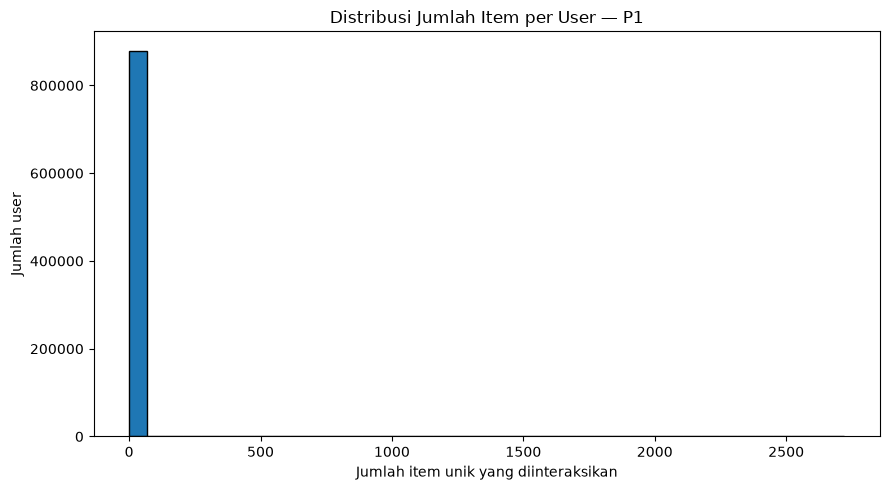

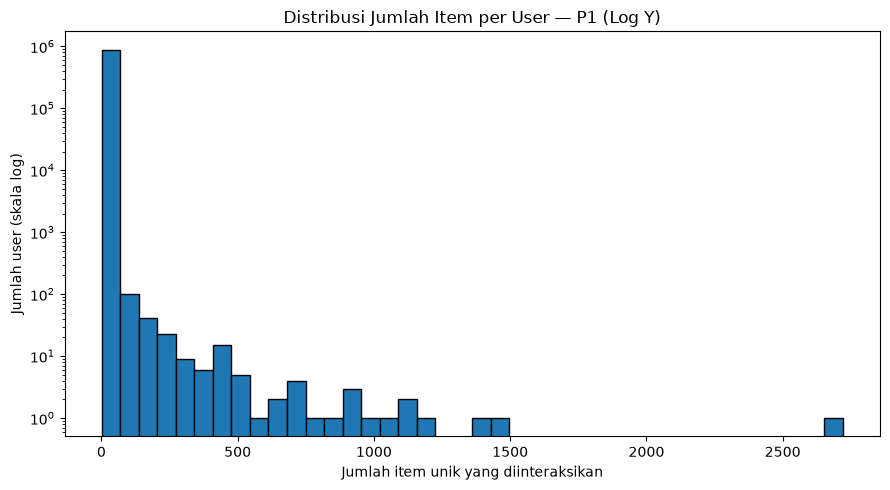

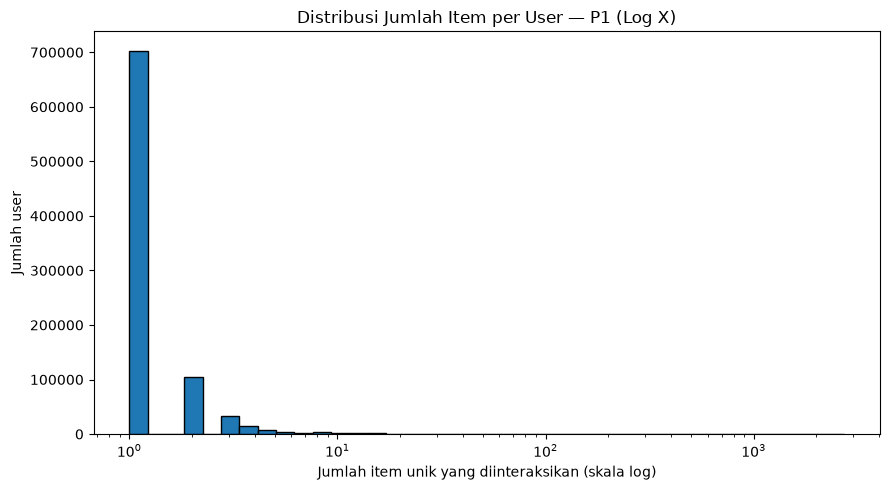

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# Menghindari nilai 0 atau negatif untuk skala log X
jumlah_item = user_activity["jumlah_item"]
jumlah_item_positif = jumlah_item[jumlah_item > 0]

# ============================================================
# 1. HISTOGRAM BIASA
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item, bins=40, edgecolor="black")
plt.title("Distribusi Jumlah Item per User — P1")
plt.xlabel("Jumlah item unik yang diinteraksikan")
plt.ylabel("Jumlah user")
plt.tight_layout()
plt.show()

# ============================================================
# 2. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU Y
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item, bins=40, edgecolor="black")
plt.yscale("log")
plt.title("Distribusi Jumlah Item per User — P1 (Log Y)")
plt.xlabel("Jumlah item unik yang diinteraksikan")
plt.ylabel("Jumlah user (skala log)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU X
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_item_positif, bins=np.logspace(
    np.log10(jumlah_item_positif.min()),
    np.log10(jumlah_item_positif.max()),
    40
), edgecolor="black")
plt.xscale("log")
plt.title("Distribusi Jumlah Item per User — P1 (Log X)")
plt.xlabel("Jumlah item unik yang diinteraksikan (skala log)")
plt.ylabel("Jumlah user")
plt.tight_layout()
plt.show()

**Plot graf bipartit menggunakan NetworkX**

VSM adalah matriks, sedangkan NetworkX digunakan untuk menampilkan hubungan user-item sebagai graf bipartit. Node dari kedua kelompok dibuat berbeda. Agar visualisasi terbaca dan tidak terlalu berat, kita pilih paling banyak 20 user dan 20 item dengan bobot interaksi tertinggi. Ini adalah subgraf visualisasi, bukan keseluruhan graf.

In [85]:
# Derajat berbobot per user dan item
user_strength = user_item_agg.groupby("visitorid")["weight"].sum()
item_strength = user_item_agg.groupby("itemid")["weight"].sum()

top_users = user_strength.nlargest(min(20, len(user_strength))).index
top_items = item_strength.nlargest(min(20, len(item_strength))).index

plot_edges = user_item_agg[
    user_item_agg["visitorid"].isin(top_users) &
    user_item_agg["itemid"].isin(top_items)
].copy()

G = nx.Graph()

for uid in top_users:
    G.add_node(f"U_{uid}", bipartite="user", node_type="user")

for iid in top_items:
    G.add_node(f"I_{iid}", bipartite="item", node_type="item")

for row in plot_edges.itertuples(index=False):
    G.add_edge(
        f"U_{row.visitorid}",
        f"I_{row.itemid}",
        weight=float(row.weight)
    )

print("Jumlah node pada graf visualisasi:", G.number_of_nodes())
print("Jumlah edge pada graf visualisasi:", G.number_of_edges())

Jumlah node pada graf visualisasi: 40
Jumlah edge pada graf visualisasi: 96


Interpretasi: node Visitor dan Item berada pada dua kelompok berbeda. Edge menghubungkan user dengan item yang pernah diinteraksikan, dan ketebalan edge menggambarkan bobot interaksi agregat.

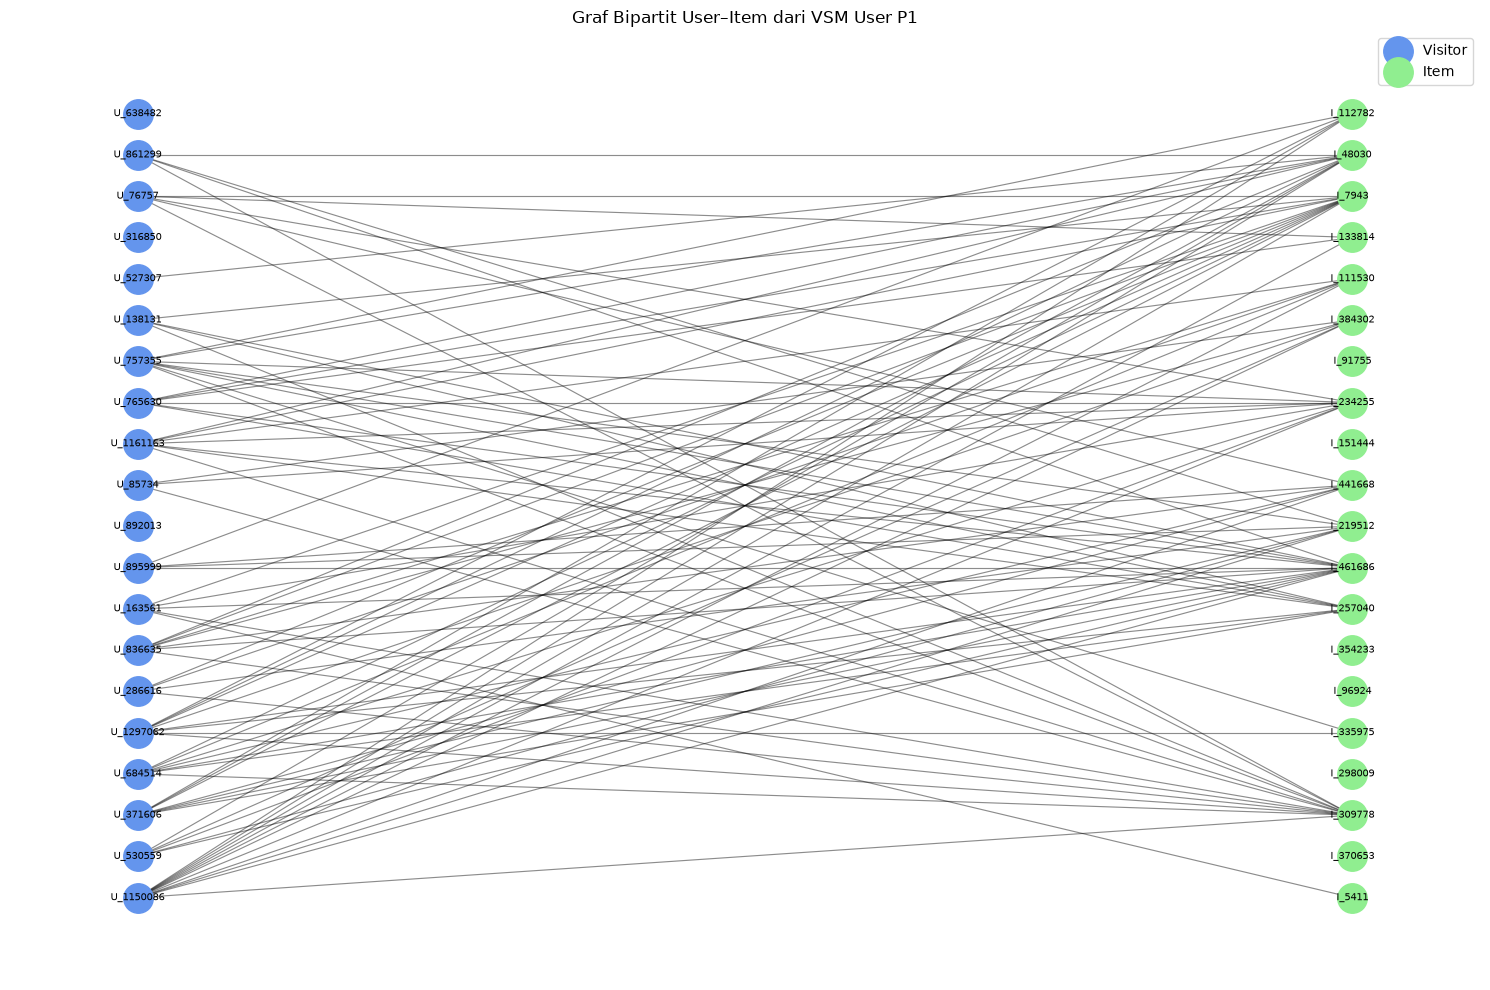

In [86]:
user_nodes = [
    n for n, d in G.nodes(data=True) if d["node_type"] == "user"
]
item_nodes = [
    n for n, d in G.nodes(data=True) if d["node_type"] == "item"
]

pos = {}

for idx, node in enumerate(user_nodes):
    pos[node] = (0, idx)

for idx, node in enumerate(item_nodes):
    pos[node] = (1, idx)

plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_color="cornflowerblue",
    node_size=450,
    label="Visitor"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_color="lightgreen",
    node_size=450,
    label="Item"
)

nx.draw_networkx_edges(
    G, pos,
    width=[
        0.5 + G[u][v]["weight"] / 3
        for u, v in G.edges()
    ],
    alpha=0.45
)

nx.draw_networkx_labels(G, pos, font_size=7)

plt.title("Graf Bipartit User–Item dari VSM User P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

mengambil 60 user dengan jumlah interaksi terbanyak agar graf mudah divisualisasikan. Setiap pasangan user yang memiliki minimal satu item bersama akan dihubungkan.

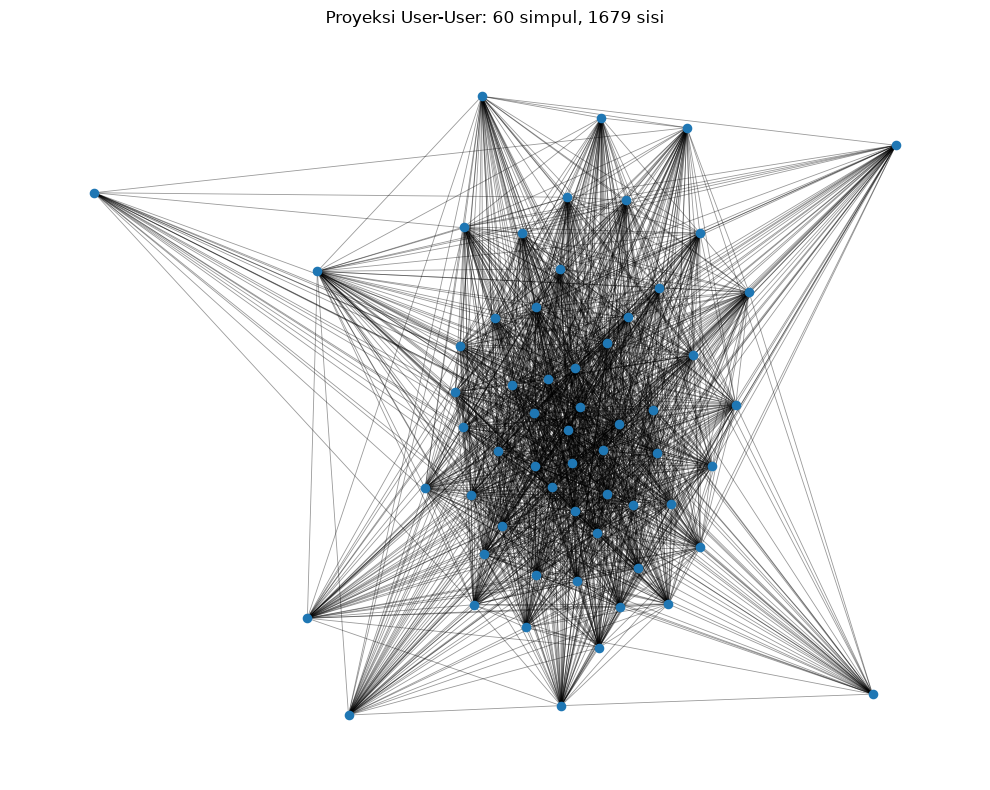

In [87]:
# ============================================================
# PROYEKSI USER-USER
# ============================================================

# Pastikan format CSR
X_user = X_user.tocsr()

# Pilih maksimal 60 user dengan jumlah item non-zero terbanyak
MAX_USERS = 60

user_degree = np.diff(X_user.indptr)
selected_user_idx = np.argsort(user_degree)[-MAX_USERS:]

# Ambil submatriks user terpilih
X_user_sample = X_user[selected_user_idx, :].tocsr()

# Bangun proyeksi User-User:
# X_user_sample @ X_user_sample.T menghitung item bersama
user_projection = X_user_sample @ X_user_sample.T

# Hilangkan diagonal (hubungan user dengan dirinya sendiri)
user_projection.setdiag(0)
user_projection.eliminate_zeros()

# Bentuk graf NetworkX
G_user = nx.Graph()

# Tambahkan node user
for idx in range(len(selected_user_idx)):
    G_user.add_node(idx)

# Tambahkan edge jika ada minimal satu item bersama
rows, cols = user_projection.nonzero()

for i, j in zip(rows, cols):
    if i < j:
        G_user.add_edge(
            i,
            j,
            weight=float(user_projection[i, j])
        )

# Visualisasi
plt.figure(figsize=(10, 8))

pos_user = nx.spring_layout(
    G_user,
    seed=42,
    k=0.5
)

nx.draw_networkx_nodes(
    G_user, pos_user,
    node_size=35,
    node_color="tab:blue"
)

nx.draw_networkx_edges(
    G_user, pos_user,
    alpha=0.4,
    width=0.6
)

plt.title(
    f"Proyeksi User-User: "
    f"{G_user.number_of_nodes()} simpul, "
    f"{G_user.number_of_edges()} sisi"
)
plt.axis("off")
plt.tight_layout()
plt.show()

Graf ini menunjukkan hubungan antara 60 pengguna (user) dengan total 1.680 garis hubungan. Titik biru mewakili pengguna, sedangkan garis abu-abu menunjukkan hubungan antar pengguna berdasarkan data yang digunakan.

Sebagian besar titik berkumpul di tengah karena banyak pengguna saling terhubung. Sementara itu, beberapa titik berada jauh dari kumpulan utama, yang menunjukkan posisi mereka berbeda dalam pola hubungan pada graf.

**JAWABAN NO.4** 
| Karakteristik | Interpretasi |
|---|---|
| **Shape** | `(877601, 191463)`, terdiri dari 877.601 baris user dan 191.463 kolom item. |
| **Jumlah vektor (user)** | Terdapat 877.601 user yang direpresentasikan sebagai vektor dalam VSM. |
| **Dimensi vektor (item)** | Setiap vektor user memiliki 191.463 dimensi yang mewakili item. |
| **Density (%)** | Sebesar 0,00078979%, menunjukkan proporsi elemen matriks yang bernilai bukan nol. |
| **Sparsity (%)** | Sebesar 99,99921021%, menunjukkan bahwa hampir seluruh elemen matriks bernilai nol. |
| **Rata-rata NNZ/vektor** | Setiap user rata-rata memiliki sekitar 1,51 item unik yang dilihat. |
| **Median NNZ/vektor** | Bernilai 1, artinya setidaknya separuh user memiliki paling banyak satu item unik yang dilihat. |
| **Minimum NNZ/vektor** | Bernilai 1, menunjukkan jumlah item unik paling sedikit yang dilihat oleh seorang user. |
| **Maksimum NNZ/vektor** | Bernilai 2.716, menunjukkan jumlah item unik terbanyak yang dilihat oleh seorang user. |
| **Memori CSR (MB)** | Sebesar 13,47 MB. Format CSR menyimpan elemen bukan nol beserta indeksnya sehingga lebih hemat memori dibandingkan matriks penuh. |

### No. 5 : Membentuk VSM Item dari P1

VSM Item menggunakan informasi interaksi yang sama, tetapi sudut pandangnya dibalik. Setiap baris adalah item dan setiap kolom adalah user. Nilai bobot tetap sama dengan VSM User.

In [116]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse

# ============================================================
# PEMBENTUKAN VECTOR SPACE MODEL (VSM ITEM)
# VIEW ONLY - P1
# ============================================================

# 1. Pastikan X_user berformat CSR
if not issparse(X_user):
    X_user = csr_matrix(X_user)
else:
    X_user = X_user.tocsr()

# 2. Transpose VSM User menjadi VSM Item
# Baris = item
# Kolom = user
X_item = X_user.T.tocsr()

# 3. Pertahankan urutan ID sesuai matriks
item_ids_vsm = item_ids.copy()
user_ids_vsm = user_ids.copy()

# ============================================================
# KARAKTERISTIK VSM ITEM
# ============================================================

n_items_vsm, n_users_vsm = X_item.shape

nnz = X_item.nnz
total_elements = n_items_vsm * n_users_vsm

density = (
    nnz / total_elements * 100
    if total_elements > 0 else 0
)

sparsity = (
    100 - density
    if total_elements > 0 else 0
)

# Jumlah user yang melihat setiap item
nnz_per_vector = np.diff(X_item.indptr)

mean_nnz = (
    np.mean(nnz_per_vector)
    if n_items_vsm > 0 else 0
)

median_nnz = (
    np.median(nnz_per_vector)
    if n_items_vsm > 0 else 0
)

min_nnz = (
    np.min(nnz_per_vector)
    if n_items_vsm > 0 else 0
)

max_nnz = (
    np.max(nnz_per_vector)
    if n_items_vsm > 0 else 0
)

# Memori CSR
memory_bytes = (
    X_item.data.nbytes
    + X_item.indices.nbytes
    + X_item.indptr.nbytes
)

memory_mb = memory_bytes / (1024 ** 2)

# ============================================================
# VALIDASI VSM ITEM
# ============================================================

assert X_item.shape == (len(item_ids_vsm), len(user_ids_vsm)), (
    "Shape X_item tidak sesuai dengan daftar ID item dan user."
)

assert X_item.nnz == X_user.nnz, (
    "Jumlah non-zero VSM Item berbeda dari VSM User."
)

# ============================================================
# TABEL KARAKTERISTIK VSM ITEM
# ============================================================

vsm_item_characteristics = pd.DataFrame({
    "Karakteristik": [
        "Jenis event",
        "Periode data",
        "Representasi",
        "Shape",
        "Jumlah vektor (item)",
        "Dimensi vektor (user)",
        "NNZ",
        "Total elemen matriks",
        "Density (%)",
        "Sparsity (%)",
        "Rata-rata NNZ/vektor",
        "Median NNZ/vektor",
        "Minimum NNZ/vektor",
        "Maksimum NNZ/vektor",
        "Memori CSR (MB)"
    ],
    "VSM Item": [
        "view saja",
        "P1",
        "Baris=item, kolom=user",
        str(X_item.shape),
        f"{n_items_vsm:,}",
        f"{n_users_vsm:,}",
        f"{nnz:,}",
        f"{total_elements:,}",
        f"{density:.8f}%",
        f"{sparsity:.8f}%",
        f"{mean_nnz:.2f}",
        f"{median_nnz:.2f}",
        f"{min_nnz:,}",
        f"{max_nnz:,}",
        f"{memory_mb:.2f}"
    ]
})

display(
    vsm_item_characteristics.set_index("Karakteristik")
)

,VSM Item
Karakteristik,
Jenis event,view saja
Periode data,P1
Representasi,"Baris=item, kolom=user"
Shape,"(191463, 877601)"
Jumlah vektor (item),"191,463"
Dimensi vektor (user),"877,601"
NNZ,"1,327,072"
Total elemen matriks,"168,028,120,263"
Density (%),0.00078979%


**Menyimpan VSM Item**

In [90]:
save_npz(
    os.path.join(OUTPUT_DIR, "vsm_item_P1.npz"),
    X_item
)

pd.DataFrame({"itemid": item_ids_vsm}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_item_row_ids.csv"),
    index=False
)

pd.DataFrame({"visitorid": user_ids_vsm}).to_csv(
    os.path.join(OUTPUT_DIR, "vsm_item_column_ids.csv"),
    index=False
)

print("VSM Item dan metadata ID berhasil disimpan.")

VSM Item dan metadata ID berhasil disimpan.


Visualisasi jumlah user per item

In [91]:
# ============================================================
# STATISTIK AKTIVITAS ITEM
# ============================================================

item_activity = (
    user_item_agg.groupby("itemid")
    .agg(
        jumlah_user=("visitorid", "nunique"),
        total_bobot=("weight", "sum")
    )
    .reset_index()
)

print("Statistik jumlah user per item:")
display(
    item_activity["jumlah_user"]
    .describe()
    .to_frame("statistik")
)

print("\n10 item dengan jumlah user terbanyak:")
display(
    item_activity
    .sort_values("jumlah_user", ascending=False)
    .head(10)
)

Statistik jumlah user per item:


,statistik
count,191463.000000
mean,6.931219
std,18.638083
min,1.000000
25%,1.000000
50%,2.000000
75%,6.000000
max,1728.000000



10 item dengan jumlah user terbanyak:


,itemid,jumlah_user,total_bobot
170588,5411,1728,1728.0
123415,370653,1058,1058.0
95540,309778,955,955.0
90187,298009,936,936.0
107504,335975,852,852.0
190075,96924,808,808.0
115941,354233,736,736.0
71528,257040,727,727.0
164809,461686,701,701.0
54375,219512,647,647.0


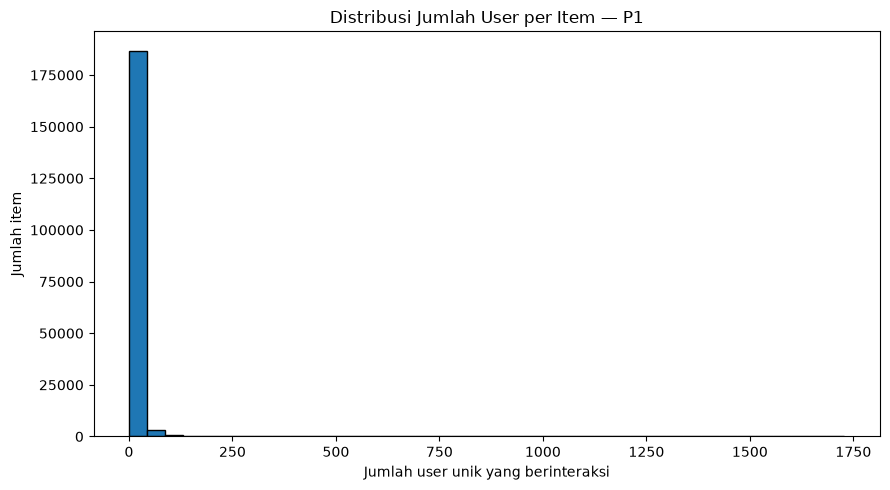

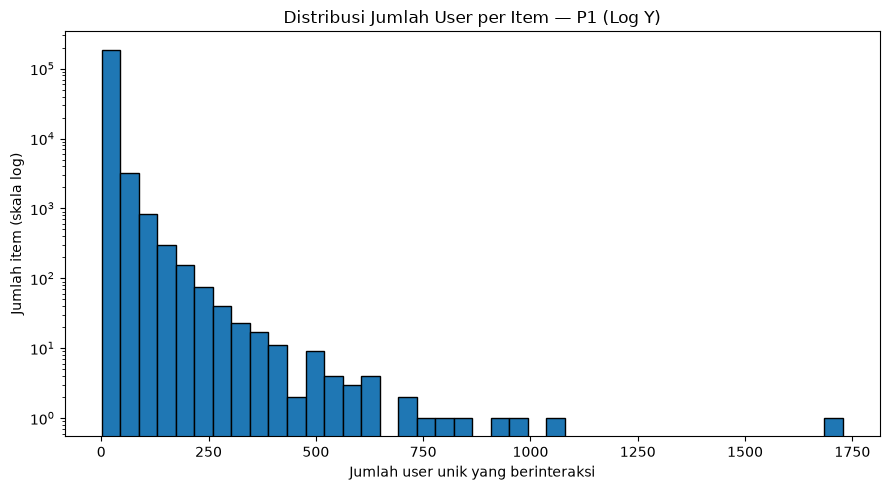

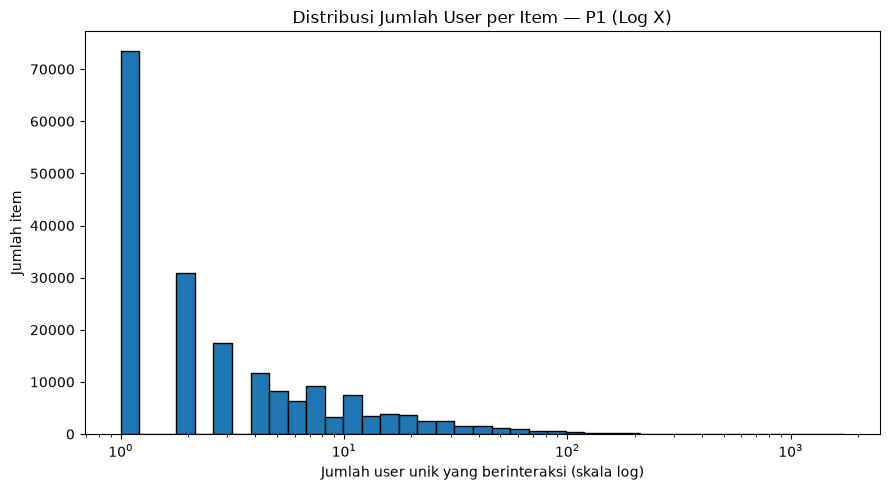

In [92]:
import matplotlib.pyplot as plt
import numpy as np

jumlah_user = item_activity["jumlah_user"]
jumlah_user_positif = jumlah_user[jumlah_user > 0]

# ============================================================
# 1. HISTOGRAM BIASA
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_user, bins=40, edgecolor="black")
plt.title("Distribusi Jumlah User per Item — P1")
plt.xlabel("Jumlah user unik yang berinteraksi")
plt.ylabel("Jumlah item")
plt.tight_layout()
plt.show()

# ============================================================
# 2. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU Y
# ============================================================
plt.figure(figsize=(9, 5))
plt.hist(jumlah_user, bins=40, edgecolor="black")
plt.yscale("log")
plt.title("Distribusi Jumlah User per Item — P1 (Log Y)")
plt.xlabel("Jumlah user unik yang berinteraksi")
plt.ylabel("Jumlah item (skala log)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. HISTOGRAM DENGAN SKALA LOGARITMIK PADA SUMBU X
# ============================================================
if not jumlah_user_positif.empty:
    bins_log = np.logspace(
        np.log10(jumlah_user_positif.min()),
        np.log10(jumlah_user_positif.max()),
        40
    )

    plt.figure(figsize=(9, 5))
    plt.hist(jumlah_user_positif, bins=bins_log, edgecolor="black")
    plt.xscale("log")
    plt.title("Distribusi Jumlah User per Item — P1 (Log X)")
    plt.xlabel("Jumlah user unik yang berinteraksi (skala log)")
    plt.ylabel("Jumlah item")
    plt.tight_layout()
    plt.show()

**Plot graf bipartit dari perspektif VSM Item**

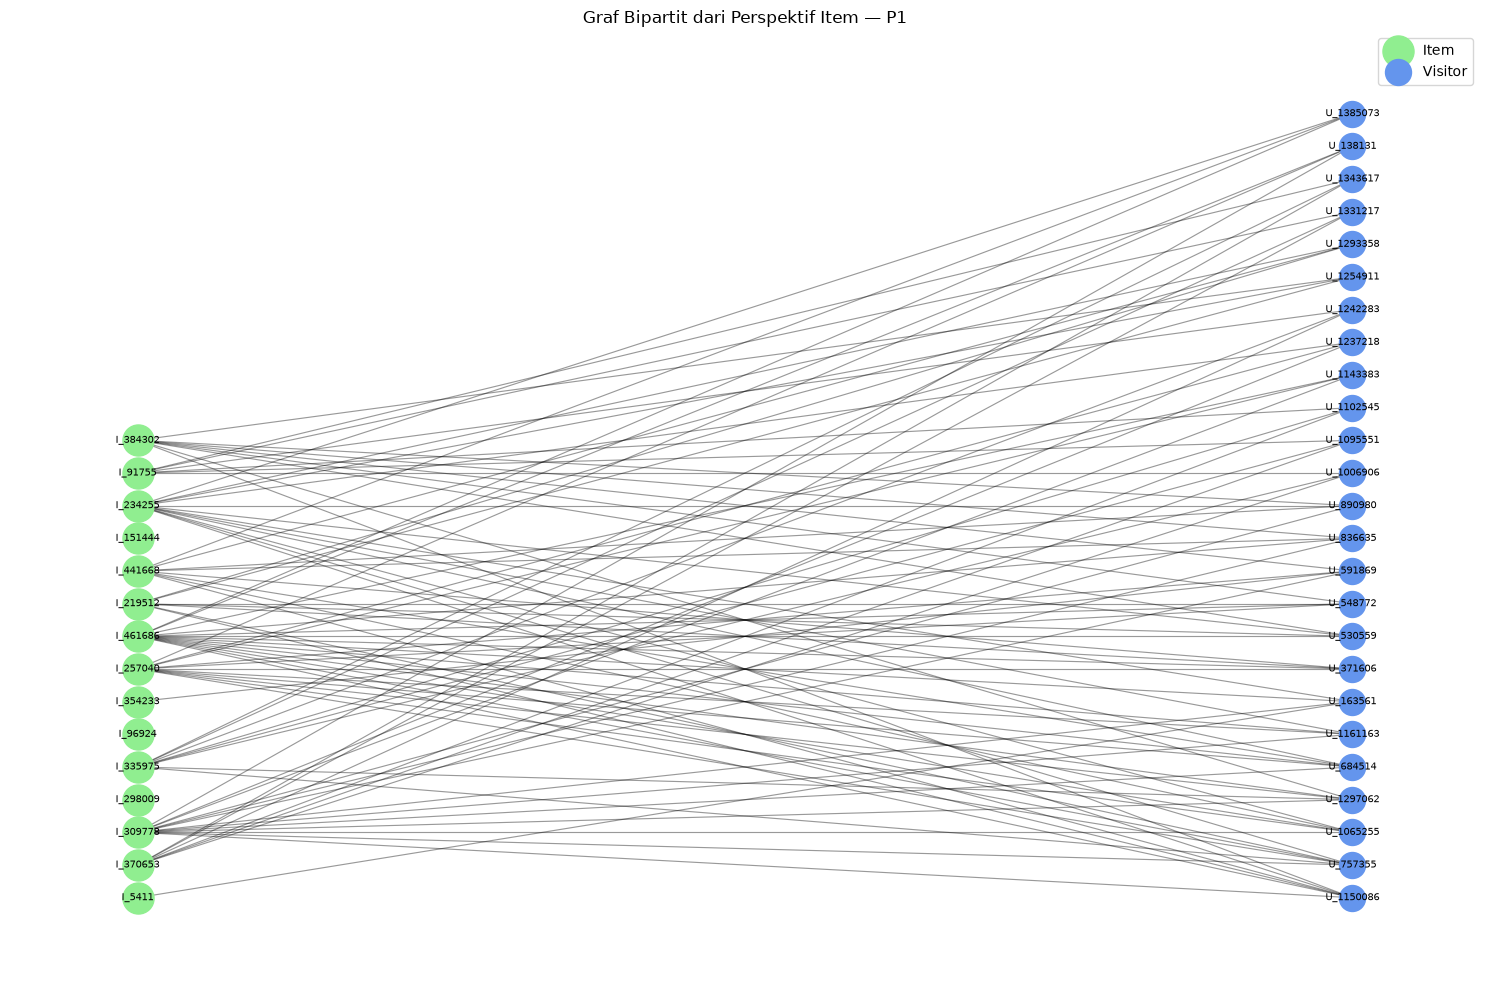

Jumlah node pada graf item-view: 40
Jumlah edge pada graf item-view: 95


In [93]:
top_items_graph = item_activity.nlargest(
    min(15, len(item_activity)), "jumlah_user"
)["itemid"]

edges_item_view = user_item_agg[
    user_item_agg["itemid"].isin(top_items_graph)
].copy()

# Batasi user agar plot tidak terlalu padat
top_users_graph = (
    edges_item_view.groupby("visitorid")["weight"]
    .sum()
    .nlargest(25)
    .index
)

edges_item_view = edges_item_view[
    edges_item_view["visitorid"].isin(top_users_graph)
]

G_item = nx.Graph()

for iid in top_items_graph:
    G_item.add_node(f"I_{iid}", node_type="item")

for uid in top_users_graph:
    G_item.add_node(f"U_{uid}", node_type="user")

for row in edges_item_view.itertuples(index=False):
    G_item.add_edge(
        f"I_{row.itemid}",
        f"U_{row.visitorid}",
        weight=float(row.weight)
    )

items_draw = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "item"
]
users_draw = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "user"
]

pos_item = {}
for idx, node in enumerate(items_draw):
    pos_item[node] = (0, idx)
for idx, node in enumerate(users_draw):
    pos_item[node] = (1, idx)

plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=items_draw,
    node_color="lightgreen",
    node_size=500,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=users_draw,
    node_color="cornflowerblue",
    node_size=350,
    label="Visitor"
)

nx.draw_networkx_edges(
    G_item, pos_item,
    width=[
        0.5 + G_item[u][v]["weight"] / 3
        for u, v in G_item.edges()
    ],
    alpha=0.4
)

nx.draw_networkx_labels(G_item, pos_item, font_size=7)

plt.title("Graf Bipartit dari Perspektif Item — P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node pada graf item-view:", G_item.number_of_nodes())
print("Jumlah edge pada graf item-view:", G_item.number_of_edges())

mengambil maksimal 40 item dengan jumlah user terbanyak. Dua item terhubung jika pernah diakses oleh user yang sama.

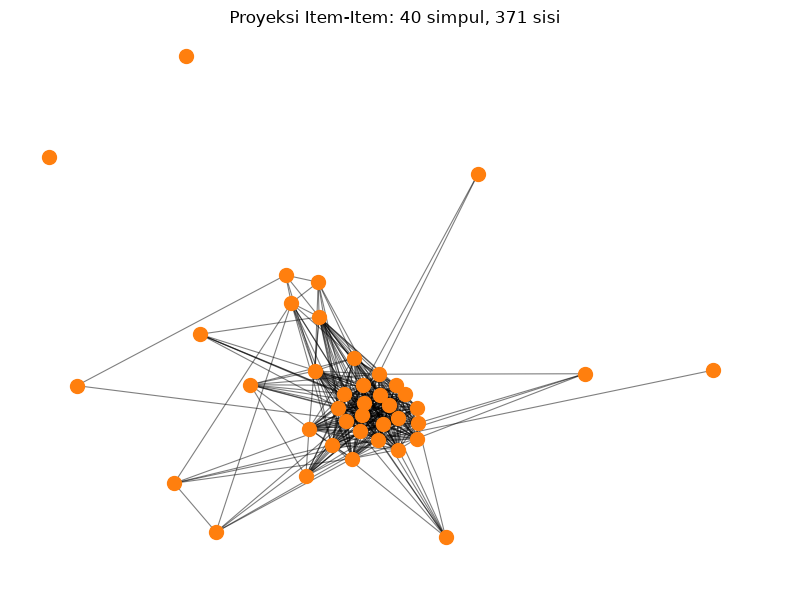

In [94]:
# ============================================================
# PROYEKSI ITEM-ITEM
# ============================================================

X_item = X_item.tocsr()

MAX_ITEMS = 40

# Jumlah user yang berinteraksi dengan setiap item
item_degree = np.diff(X_item.indptr)

# Pilih maksimal 12 item dengan user terbanyak
selected_item_idx = np.argsort(item_degree)[-MAX_ITEMS:]

# Submatriks item terpilih
X_item_sample = X_item[selected_item_idx, :].tocsr()

# X_item_sample @ X_item_sample.T menghitung user bersama
item_projection = X_item_sample @ X_item_sample.T

# Hapus hubungan item dengan dirinya sendiri
item_projection.setdiag(0)
item_projection.eliminate_zeros()

# Bentuk graf
G_item = nx.Graph()

for idx in range(len(selected_item_idx)):
    G_item.add_node(idx)

rows, cols = item_projection.nonzero()

for i, j in zip(rows, cols):
    if i < j:
        G_item.add_edge(
            i,
            j,
            weight=float(item_projection[i, j])
        )

# Visualisasi
plt.figure(figsize=(8, 6))

pos_item = nx.spring_layout(
    G_item,
    seed=42,
    k=0.8
)

nx.draw_networkx_nodes(
    G_item, pos_item,
    node_size=100,
    node_color="tab:orange"
)

nx.draw_networkx_edges(
    G_item, pos_item,
    alpha=0.5,
    width=0.8
)

plt.title(
    f"Proyeksi Item-Item: "
    f"{G_item.number_of_nodes()} simpul, "
    f"{G_item.number_of_edges()} sisi"
)
plt.axis("off")
plt.tight_layout()
plt.show()

Graf ini menggambarkan hubungan antara 40 item atau produk. Titik oranye mewakili produk, sedangkan garis abu-abu menunjukkan hubungan antarproduk berdasarkan data yang digunakan.

Sebagian besar titik berkumpul di tengah karena produk-produk tersebut memiliki banyak hubungan dengan produk lainnya. Sementara itu, beberapa titik berada jauh dari kumpulan utama karena hubungannya lebih sedikit.

**JAWABAN NO.5** 
| Karakteristik | Interpretasi |
|---|---|
| **Shape** | `(191463, 877601)`, terdiri dari 191.463 baris item dan 877.601 kolom user. |
| **Jumlah vektor (item)** | Terdapat 191.463 item yang masing-masing direpresentasikan sebagai vektor. |
| **Dimensi vektor (user)** | Setiap vektor item memiliki 877.601 dimensi yang mewakili user. |
| **Density (%)** | Sebesar 0,00078979%, menunjukkan proporsi elemen matriks yang bernilai bukan nol. |
| **Sparsity (%)** | Sebesar 99,99921021%, menunjukkan bahwa hampir seluruh elemen matriks bernilai nol. |
| **Rata-rata NNZ/vektor** | Setiap item rata-rata memiliki sekitar 6,93 user yang melihatnya. |
| **Median NNZ/vektor** | Bernilai 2, artinya setidaknya separuh item dilihat oleh paling banyak dua user. |
| **Minimum NNZ/vektor** | Bernilai 1, menunjukkan bahwa setiap item memiliki setidaknya satu user yang melihatnya. |
| **Maksimum NNZ/vektor** | Bernilai 1.728, menunjukkan bahwa item dengan interaksi terbanyak dilihat oleh 1.728 user unik. |
| **Memori CSR (MB)** | Sebesar 10,86 MB. Format CSR menyimpan elemen bukan nol beserta indeksnya sehingga lebih hemat memori dibandingkan matriks penuh. |

### Soal No.6 :  PROYEKSI YANG LEBIH BAIK (EFEKTIF DAN EFISIEN)

Untuk menentukan apakah proyeksi User–User atau Item–Item lebih baik, dilakukan pengukuran berdasarkan beberapa aspek berikut:

1. **Keterhubungan Graf** — dievaluasi melalui jumlah sisi (*edges*), kepadatan graf (*density*), dan jumlah simpul yang terisolasi (*isolated nodes*).

2. **Efisiensi Komputasi** — diukur berdasarkan waktu yang dibutuhkan untuk membentuk proyeksi dan penggunaan memori selama proses komputasi.

3. **Kualitas Struktur Graf** — dianalisis melalui jumlah komponen terhubung (*connected components*) dan rata-rata derajat simpul (*average degree*) untuk mengetahui pola hubungan dalam graf.

4. **Kelayakan untuk Rekomendasi** — dinilai berdasarkan jumlah dan pola hubungan yang dapat dimanfaatkan untuk menemukan pengguna dengan pola interaksi serupa atau item yang memiliki kesamaan berdasarkan interaksi pengguna.

**Perbandingan Proyeksi**

In [96]:
import time
import numpy as np
import pandas as pd
import networkx as nx

# ============================================================
# 1. FUNGSI ANALISIS KARAKTERISTIK GRAF
# ============================================================

def analyze_projection(G, projection_name):

    start_time = time.time()

    # --------------------------------------------------------
    # A. JUMLAH SIMPUL DAN SISI
    # --------------------------------------------------------
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    # --------------------------------------------------------
    # B. DENSITY GRAF
    # --------------------------------------------------------
    density = (
        nx.density(G)
        if n_nodes > 1 else 0
    )

    # --------------------------------------------------------
    # C. DISTRIBUSI DERAJAT SIMPUL
    # --------------------------------------------------------
    degrees = np.array(
        [degree for _, degree in G.degree()],
        dtype=np.int64
    )

    avg_degree = (
        degrees.mean()
        if len(degrees) > 0 else 0
    )

    median_degree = (
        np.median(degrees)
        if len(degrees) > 0 else 0
    )

    max_degree = (
        degrees.max()
        if len(degrees) > 0 else 0
    )

    min_degree = (
        degrees.min()
        if len(degrees) > 0 else 0
    )

    # --------------------------------------------------------
    # D. SIMPUL TERISOLASI DAN SIMPUL AKTIF
    # --------------------------------------------------------
    isolate_count = sum(
        1 for _, degree in G.degree()
        if degree == 0
    )

    active_nodes = n_nodes - isolate_count

    active_nodes_pct = (
        active_nodes / n_nodes * 100
        if n_nodes > 0 else 0
    )

    isolate_pct = (
        isolate_count / n_nodes * 100
        if n_nodes > 0 else 0
    )

    # --------------------------------------------------------
    # E. KOMPONEN TERHUBUNG
    # --------------------------------------------------------
    # Untuk graf tidak berarah, gunakan connected_components.
    # Untuk graf berarah, gunakan weakly_connected_components.
    if G.is_directed():
        components = nx.weakly_connected_components(G)
    else:
        components = nx.connected_components(G)

    component_sizes = [
        len(component) for component in components
    ]

    n_components = len(component_sizes)

    largest_component = (
        max(component_sizes)
        if component_sizes else 0
    )

    largest_component_pct = (
        largest_component / n_nodes * 100
        if n_nodes > 0 else 0
    )

    # --------------------------------------------------------
    # F. RATA-RATA DERAJAT PADA GRAF
    # --------------------------------------------------------
    # Rata-rata derajat = 2E/N untuk graf tidak berarah.
    # Nilai avg_degree di atas dihitung langsung dari simpul.
    # --------------------------------------------------------

    elapsed_time = time.time() - start_time

    return {
        "Proyeksi": projection_name,
        "Jumlah simpul": n_nodes,
        "Jumlah sisi": n_edges,
        "Density (%)": density * 100,
        "Rata-rata derajat": avg_degree,
        "Median derajat": median_degree,
        "Derajat minimum": min_degree,
        "Derajat maksimum": max_degree,
        "Simpul terisolasi": isolate_count,
        "Simpul terisolasi (%)": isolate_pct,
        "Simpul aktif (%)": active_nodes_pct,
        "Jumlah komponen": n_components,
        "Simpul komponen terbesar (%)": largest_component_pct,
        "Waktu analisis (detik)": elapsed_time
    }


# ============================================================
# 2. ANALISIS GRAF USER-USER DAN ITEM-ITEM
# ============================================================

user_result = analyze_projection(
    G_user,
    "User-User"
)

item_result = analyze_projection(
    G_item,
    "Item-Item"
)

comparison = pd.DataFrame([
    user_result,
    item_result
]).set_index("Proyeksi")

# ============================================================
# 3. TAMPILKAN HASIL PERBANDINGAN
# ============================================================

display(comparison.round(4))

,Jumlah simpul,Jumlah sisi,Density (%),Rata-rata derajat,Median derajat,Derajat minimum,Derajat maksimum,Simpul terisolasi,Simpul terisolasi (%),Simpul aktif (%),Jumlah komponen,Simpul komponen terbesar (%),Waktu analisis (detik)
Proyeksi,,,,,,,,,,,,,
User-User,60,1679,94.8588,55.9667,57.0,24,59,0,0.0,100.0,1,100.0,0.001
Item-Item,40,371,47.5641,18.5500,24.5,0,31,2,5.0,95.0,3,95.0,0.001


**Tentukan proyeksi yang lebih baik berdasarkan struktur graf**

membandingkan proporsi simpul aktif, density, dan rata-rata derajat.membandingkan proporsi simpul aktif, density, dan rata-rata derajat.

In [97]:
# ============================================================
# 3. PERBANDINGAN INDIKATOR STRUKTUR
# ============================================================

print("========== HASIL PERBANDINGAN ==========")

for name, result in [
    ("User-User", user_result),
    ("Item-Item", item_result)
]:
    print(f"\nProyeksi {name}")
    print(f"Jumlah sisi             : {result['Jumlah sisi']}")
    print(f"Density                  : {result['Density (%)']:.4f}%")
    print(f"Rata-rata derajat        : {result['Rata-rata derajat']:.2f}")
    print(f"Simpul terisolasi        : {result['Simpul terisolasi']}")
    print(f"Simpul aktif             : {result['Simpul aktif (%)']:.2f}%")
    print(
        "Komponen terbesar       : "
        f"{result['Simpul komponen terbesar (%)']:.2f}% simpul"
    )

# Perbandingan berdasarkan jumlah sisi dan simpul aktif
if (
    user_result["Simpul aktif (%)"] > item_result["Simpul aktif (%)"]
    and user_result["Jumlah sisi"] > item_result["Jumlah sisi"]
):
    print(
        "\nKesimpulan struktural: User-User lebih terhubung "
        "pada graf yang sedang dianalisis."
    )
elif (
    item_result["Simpul aktif (%)"] > user_result["Simpul aktif (%)"]
    and item_result["Jumlah sisi"] > user_result["Jumlah sisi"]
):
    print(
        "\nKesimpulan struktural: Item-Item lebih terhubung "
        "pada graf yang sedang dianalisis."
    )
else:
    print(
        "\nKesimpulan: tidak ada pemenang berdasarkan dua indikator "
        "tersebut saja. Periksa seluruh metrik dan tujuan analisis."
    )

========== HASIL PERBANDINGAN ==========

Proyeksi User-User
Jumlah sisi             : 1679
Density                  : 94.8588%
Rata-rata derajat        : 55.97
Simpul terisolasi        : 0
Simpul aktif             : 100.00%
Komponen terbesar       : 100.00% simpul

Proyeksi Item-Item
Jumlah sisi             : 371
Density                  : 47.5641%
Rata-rata derajat        : 18.55
Simpul terisolasi        : 2
Simpul aktif             : 95.00%
Komponen terbesar       : 95.00% simpul

Kesimpulan struktural: User-User lebih terhubung pada graf yang sedang dianalisis.


Visualisasi Perbandingan Metriks

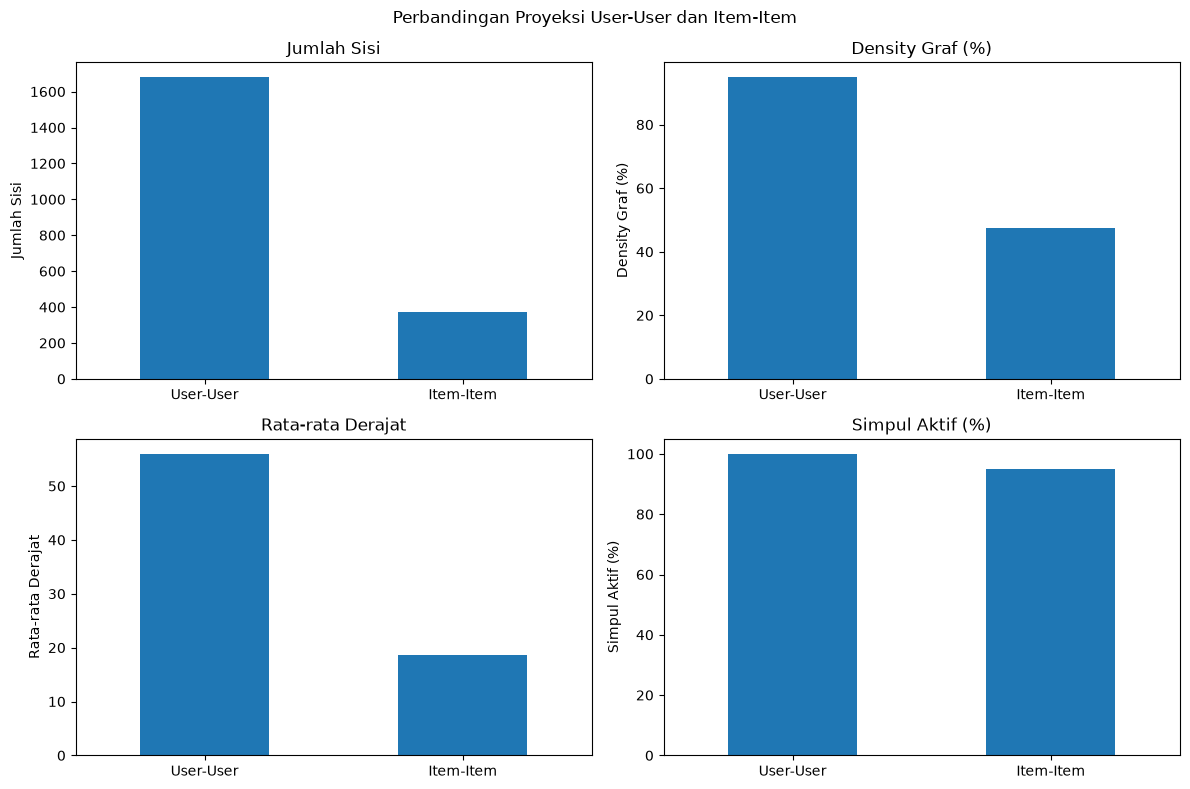

In [98]:
import matplotlib.pyplot as plt

metrics = [
    ("Jumlah sisi", "Jumlah Sisi"),
    ("Density (%)", "Density Graf (%)"),
    ("Rata-rata derajat", "Rata-rata Derajat"),
    ("Simpul aktif (%)", "Simpul Aktif (%)")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metrics):
    comparison[column].plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Perbandingan Proyeksi User-User dan Item-Item")
plt.tight_layout()
plt.show()

Proyeksi User-User
Jumlah sisi             : 1679
Density                  : 94.8588%
Rata-rata derajat        : 55.97
Simpul terisolasi        : 0
Simpul aktif             : 100.00%
Komponen terbesar       : 100.00% simpul

Proyeksi Item-Item
Jumlah sisi             : 371
Density                  : 47.5641%
Rata-rata derajat        : 18.55
Simpul terisolasi        : 2
Simpul aktif             : 95.00%
Komponen terbesar       : 95.00% simpul

**JAWABAN NO.6** 
Proyeksi User-User lebih efektif
- Proyeksi User-User: tidak memiliki simpul terisolasi, seluruh simpul aktif, dan 100% simpul berada dalam komponen terbesar. Artinya, seluruh user saling terhubung melalui jalur graf, sehingga berpotensi mendukung pencarian pengguna dengan pola interaksi serupa.

- Proyeksi Item-Item: memiliki 371 sisi, density 47,5641%, dan rata-rata derajat 18,55. Jumlah sisi yang lebih sedikit membuat graf ini relatif lebih ringan untuk diproses. Namun, terdapat dua simpul terisolasi dan hanya 95% simpul berada dalam komponen terbesar, sehingga sebagian item tidak terhubung dengan item lain.

### Soal No.7 : Perhitungan Similarity yang akan disimpan ke Neo4j

**Pemilihan user acuan** dipakai oleh soal no 7 dan soal bagian analysis

1. Identifikasi user: Memilih user yang memiliki interaksi pada P1 dan P2, mencakup VIEW, ADDTOCART, dan TRANSACTION.

2. Penentuan ground truth: Mengidentifikasi item unik pada P2 yang belum pernah memiliki interaksi dengan user tersebut pada P1.

3. Filter kandidat: user acuan yang dipilih memiliki tepat 5 item ground truth dan jumlah item unik yang berinteraksi dengannya paling banyak pada P1

4. Pemilihan user acuan: Memilih satu user secara acak menggunakan random_state=42 dan menyimpan kelima item ground truth untuk evaluasi rekomendasi.

#### tes similarity

**Mengambil kandidat user acuan dari Neo4j**

Memilih maksimal 500 user kandidat dari Neo4j yang memiliki tepat 5 item ground truth pada periode P2 dan tersedia dalam VSM User periode P1. Kandidat tersebut akan digunakan untuk menguji performa sistem rekomendasi, dengan data P1 sebagai dasar rekomendasi dan data P2 sebagai acuan evaluasi.

In [100]:
# ============================================================
# 2.1 AMBIL KANDIDAT DARI NEO4J
# ============================================================

# Gunakan koneksi driver yang sudah Anda buat sebelumnya.
# Contoh jika belum ada:
# URI = "neo4j://127.0.0.1:7687"
# AUTH = ("neo4j", "PASSWORD_ANDA")
# driver = GraphDatabase.driver(URI, auth=AUTH)

MAX_CANDIDATES = 500

candidate_query = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE r.period = 'P1'
  AND type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
WITH u, collect(DISTINCT toString(i.itemId)) AS p1_items

MATCH (u)-[r2]->(i2:Item)
WHERE r2.period = 'P2'
  AND type(r2) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
  AND NOT toString(i2.itemId) IN p1_items

WITH u, p1_items, count(DISTINCT i2.itemId) AS ground_truth_count
WHERE ground_truth_count = 5

RETURN
    toString(u.visitorId) AS visitor_id,
    size(p1_items) AS p1_item_count
ORDER BY p1_item_count DESC
LIMIT $limit
"""

with driver.session() as session:
    candidate_records = session.run(
        candidate_query,
        limit=MAX_CANDIDATES
    ).data()

candidates = pd.DataFrame(candidate_records)

if candidates.empty:
    raise ValueError(
        "Tidak ditemukan kandidat dengan tepat 5 item ground truth P2."
    )

# Pastikan user tersedia dalam VSM
candidates["visitor_id"] = candidates["visitor_id"].astype(str)
candidates = candidates[
    candidates["visitor_id"].isin(user_to_idx)
].drop_duplicates("visitor_id").reset_index(drop=True)

if candidates.empty:
    raise ValueError(
        "Kandidat Neo4j tidak ditemukan dalam VSM User P1."
    )

print("Jumlah kandidat valid dalam VSM:", len(candidates))
print(candidates.head(10).to_string(index=False))

Jumlah kandidat valid dalam VSM: 247
visitor_id  p1_item_count
    550789            144
   1015928             99
    269127             80
   1336659             49
    835779             48
    244620             46
   1385214             42
    739007             42
    347643             39
    349829             32


Terdapat 247 kandidat user acuan. user diurutkan berdasarkan jumlah item P1 dari yang terbanyak dengan alasan semakin banyak item unik yang pernah diakses pada P1, semakin banyak informasi yang tersedia untuk membentuk profil preferensi user dan menghitung kemiripan dengan user lain. Dengan demikian, proses rekomendasi berbasis user similarity berpotensi menghasilkan rekomendasi yang lebih relevan karena didukung oleh pola interaksi historis yang lebih informatif.

**Menghitung cosine similarity dari vsm user**

In [119]:
# ============================================================
# 3. HITUNG COSINE SIMILARITY DAN TAMPILKAN TOP-5 USER
# ============================================================

TOP_K = 5

# Normalisasi setiap baris VSM User.
# Dot product pada matriks ternormalisasi menghasilkan cosine similarity.
X_norm = normalize(
    X_user, norm="l2", axis=1, copy=True
).tocsr()

similarity_records = []

for row in candidates.itertuples(index=False):

    ref_id = str(row.visitor_id)
    ref_idx = user_to_idx[ref_id]

    # Hitung similarity user acuan terhadap seluruh user.
    similarity_row = (X_norm.getrow(ref_idx) @ X_norm.T).tocoo()

    neighbor_idx = similarity_row.col
    similarity_values = similarity_row.data

    # Keluarkan user acuan sendiri dan similarity nol.
    valid = (
        (neighbor_idx != ref_idx)
        & (similarity_values > 0)
    )

    neighbor_idx = neighbor_idx[valid]
    similarity_values = similarity_values[valid]

    if len(neighbor_idx) == 0:
        continue

    # Urutkan similarity dari terbesar ke terkecil.
    top_positions = np.argsort(similarity_values)[::-1][:TOP_K]

    for rank, pos in enumerate(top_positions, start=1):
        similarity_records.append({
            "visitor_id": ref_id,
            "neighbor_id": str(user_ids[neighbor_idx[pos]]),
            "cosine_similarity": float(similarity_values[pos]),
            "rank": rank
        })

similarity_df = pd.DataFrame(similarity_records)

if similarity_df.empty:
    raise ValueError(
        "Tidak ditemukan user dengan cosine similarity positif."
    )

# ============================================================
# 4. TAMPILKAN 5 USER TERDEKAT UNTUK SETIAP USER ACUAN
# ============================================================

for ref_id, group in similarity_df.groupby("visitor_id", sort=False):
    group = group.sort_values(
        "cosine_similarity", ascending=False
    ).head(TOP_K)

    print(f"\nUser acuan: {ref_id}")
    print(
        group[
            ["rank", "neighbor_id", "cosine_similarity"]
        ].to_string(index=False)
    )

print("\n========== RINGKASAN ==========")
print("Jumlah relasi similarity:", len(similarity_df))
print("Jumlah user acuan:", similarity_df["visitor_id"].nunique())


User acuan: 550789
 rank neighbor_id  cosine_similarity
    1      143930           0.170103
    2      958890           0.136083
    3      917791           0.130437
    4      972009           0.125988
    5     1333313           0.125000

User acuan: 1015928
 rank neighbor_id  cosine_similarity
    1      521429           0.253546
    2      264804           0.223607
    3     1254846           0.200000
    4      715705           0.197642
    5      321823           0.193649

User acuan: 269127
 rank neighbor_id  cosine_similarity
    1      186080           0.256495
    2      626545           0.253917
    3     1100982           0.243332
    4      732805           0.234146
    5      441913           0.234146

User acuan: 1336659
 rank neighbor_id  cosine_similarity
    1     1227214           0.247436
    2     1188859           0.206197
    3      338577           0.202031
    4      529974           0.202031
    5      476281           0.202031

User acuan: 835779
 rank neig

In [101]:
# ============================================================
# 3. HITUNG COSINE SIMILARITY DARI VSM
# ============================================================

TOP_K = 5
RANDOM_SEED = 42

# Normalisasi setiap baris VSM.
# Untuk matriks ternormalisasi, dot product = cosine similarity.
X_norm = normalize(X_user, norm="l2", axis=1, copy=True).tocsr()

similarity_records = []

for row in candidates.itertuples(index=False):
    ref_id = str(row.visitor_id)
    ref_idx = user_to_idx[ref_id]

    # Similarity satu user acuan terhadap seluruh user di VSM.
    similarity_row = X_norm.getrow(ref_idx) @ X_norm.T

    # Ubah ke format pasangan (indeks user, nilai similarity).
    similarity_row = similarity_row.tocoo()

    neighbor_idx = similarity_row.col
    similarity_values = similarity_row.data

    # Hilangkan user acuan itu sendiri dan similarity nol.
    valid = (
        (neighbor_idx != ref_idx)
        & (similarity_values > 0)
    )

    neighbor_idx = neighbor_idx[valid]
    similarity_values = similarity_values[valid]

    if len(neighbor_idx) == 0:
        continue

    # Ambil Top-K dengan similarity terbesar.
    k = min(TOP_K, len(similarity_values))
    top_positions = np.argpartition(
        similarity_values, -k
    )[-k:]

    top_positions = top_positions[
        np.argsort(similarity_values[top_positions])[::-1]
    ]

    for rank, pos in enumerate(top_positions, start=1):
        similarity_records.append({
            "visitor_id": ref_id,
            "neighbor_id": str(user_ids[neighbor_idx[pos]]),
            "cosine_similarity": float(similarity_values[pos]),
            "rank": rank
        })

similarity_df = pd.DataFrame(similarity_records)

if similarity_df.empty:
    raise ValueError(
        "Tidak ada pasangan user dengan cosine similarity positif."
    )

print("Jumlah relasi similarity yang dihitung:", len(similarity_df))
print("Jumlah user sumber:", similarity_df["visitor_id"].nunique())
print("Contoh hasil similarity:")
print(similarity_df.head(15).to_string(index=False))

Jumlah relasi similarity yang dihitung: 1151
Jumlah user sumber: 242
Contoh hasil similarity:
visitor_id neighbor_id  cosine_similarity  rank
    550789      143930           0.170103     1
    550789      958890           0.136083     2
    550789      917791           0.130437     3
    550789      972009           0.125988     4
    550789     1333313           0.125000     5
   1015928      521429           0.253546     1
   1015928      264804           0.223607     2
   1015928     1254846           0.200000     3
   1015928      715705           0.197642     4
   1015928      321823           0.193649     5
    269127      186080           0.256495     1
    269127      626545           0.253917     2
    269127     1100982           0.243332     3
    269127      732805           0.234146     4
    269127      441913           0.234146     5


**Menyimpan hasil similarity ke neo4j**

In [102]:
# ============================================================
# 4. SIMPAN TOP-K SIMILARITY KE NEO4J
# ============================================================

# Hapus relasi lama dari user kandidat agar tidak tercampur
# dengan hasil perhitungan sebelumnya.
candidate_ids = candidates["visitor_id"].tolist()

delete_old_query = """
UNWIND $visitor_ids AS vid
MATCH (u:Visitor {visitorId: vid})-[r:SIMILAR_TO]->()
DELETE r
"""

# Perbarui juga jika visitorId tersimpan sebagai integer di Neo4j.
# Query di atas mengasumsikan visitorId tersimpan sebagai string.
# Jika tipe di database integer, sesuaikan properti/tipe ID.

save_similarity_query = """
UNWIND $rows AS row
MATCH (u:Visitor {visitorId: row.visitor_id})
MATCH (v:Visitor {visitorId: row.neighbor_id})
MERGE (u)-[r:SIMILAR_TO]->(v)
SET r.cosine_similarity = row.cosine_similarity,
    r.rank = row.rank,
    r.period = 'P1',
    r.method = 'VSM_COSINE',
    r.top_k = $top_k
"""

# Simpan ID sebagai string secara konsisten.
rows_to_save = similarity_df.to_dict(orient="records")

with driver.session() as session:
    # Hapus relasi lama untuk sumber kandidat.
    session.run(
        delete_old_query,
        visitor_ids=candidate_ids
    ).consume()

    # Simpan relasi baru dalam batch.
    BATCH_SIZE = 1000

    for start in range(0, len(rows_to_save), BATCH_SIZE):
        batch = rows_to_save[start:start + BATCH_SIZE]
        session.run(
            save_similarity_query,
            rows=batch,
            top_k=TOP_K
        ).consume()

print("Selesai menyimpan similarity ke Neo4j.")
print("Jumlah relasi yang dikirim:", len(rows_to_save))

Selesai menyimpan similarity ke Neo4j.
Jumlah relasi yang dikirim: 1151


**Memilih user acuan**

In [103]:
# ============================================================
# 5. PILIH USER ACUAN
# ============================================================

# Hanya pilih dari kandidat yang berhasil memiliki tetangga.
users_with_similarity = set(similarity_df["visitor_id"].unique())

selectable = candidates[
    candidates["visitor_id"].isin(users_with_similarity)
].copy()

if selectable.empty:
    raise ValueError(
        "Tidak ada kandidat yang memiliki tetangga dengan similarity positif."
    )

max_p1_count = selectable["p1_item_count"].max()

top_candidates = selectable[
    selectable["p1_item_count"] == max_p1_count
].copy()

reference_user = top_candidates.sample(
    n=1,
    random_state=RANDOM_SEED
).iloc[0]

reference_id = str(reference_user["visitor_id"])

print("========== USER ACUAN TERPILIH ==========")
print("Visitor ID               :", reference_id)
print("Jumlah item unik P1       :", int(reference_user["p1_item_count"]))
print("Jumlah ground truth P2    : 5")
print("Jumlah tetangga tersimpan :", int(
    (similarity_df["visitor_id"] == reference_id).sum()
))

========== USER ACUAN TERPILIH ==========
Visitor ID               : 550789
Jumlah item unik P1       : 144
Jumlah ground truth P2    : 5
Jumlah tetangga tersimpan : 5


User acuan terpilih adalah 550789, dapat dipastikan user tersebut ada di P1 dan P2

**Mendapatkan 5 user dengan similarity tertinggi**

In [104]:
# ============================================================
# 6. VERIFIKASI TOP-5 TETANGGA DI NEO4J
# ============================================================

verify_query = """
MATCH (u:Visitor)-[r:SIMILAR_TO]->(v:Visitor)
WHERE toString(u.visitorId) = $visitor_id
  AND r.period = 'P1'
  AND r.method = 'VSM_COSINE'
RETURN
    toString(u.visitorId) AS visitor_id,
    toString(v.visitorId) AS neighbor_id,
    r.cosine_similarity AS cosine_similarity,
    r.rank AS rank
ORDER BY r.rank ASC
LIMIT 5
"""

with driver.session() as session:
    neighbor_results = session.run(
        verify_query,
        visitor_id=reference_id
    ).data()

neighbors_df = pd.DataFrame(neighbor_results)

print("========== TOP-5 NEIGHBOR USER ACUAN ==========")
if neighbors_df.empty:
    print("Tidak ditemukan relasi. Periksa tipe visitorId di Neo4j.")
else:
    print(neighbors_df.to_string(index=False))

========== TOP-5 NEIGHBOR USER ACUAN ==========
visitor_id neighbor_id  cosine_similarity  rank
    550789      143930           0.170103     1
    550789      958890           0.136083     2
    550789      917791           0.130437     3
    550789      972009           0.125988     4
    550789     1333313           0.125000     5


**JAWABAN NO 7A** didapat 5 records user dengan similarity tertinggi dengan user acuan yaitu user dengan id 143930 (0.170103), 958890 (0.136083), 917791 (0.130437 ), 972009 (0.125988), dan 1333313  (0.125000 )

**JAWABAN NO.7B** Similarity berhasil tersimpan di neo4j. setelah di cek dengan cypher menghasilkan record yang sama seperti pada python

### Soal No.8 : kondisi graf sebelum dan sesudah similarity

**Graf sebelum similarity pada user acuan**

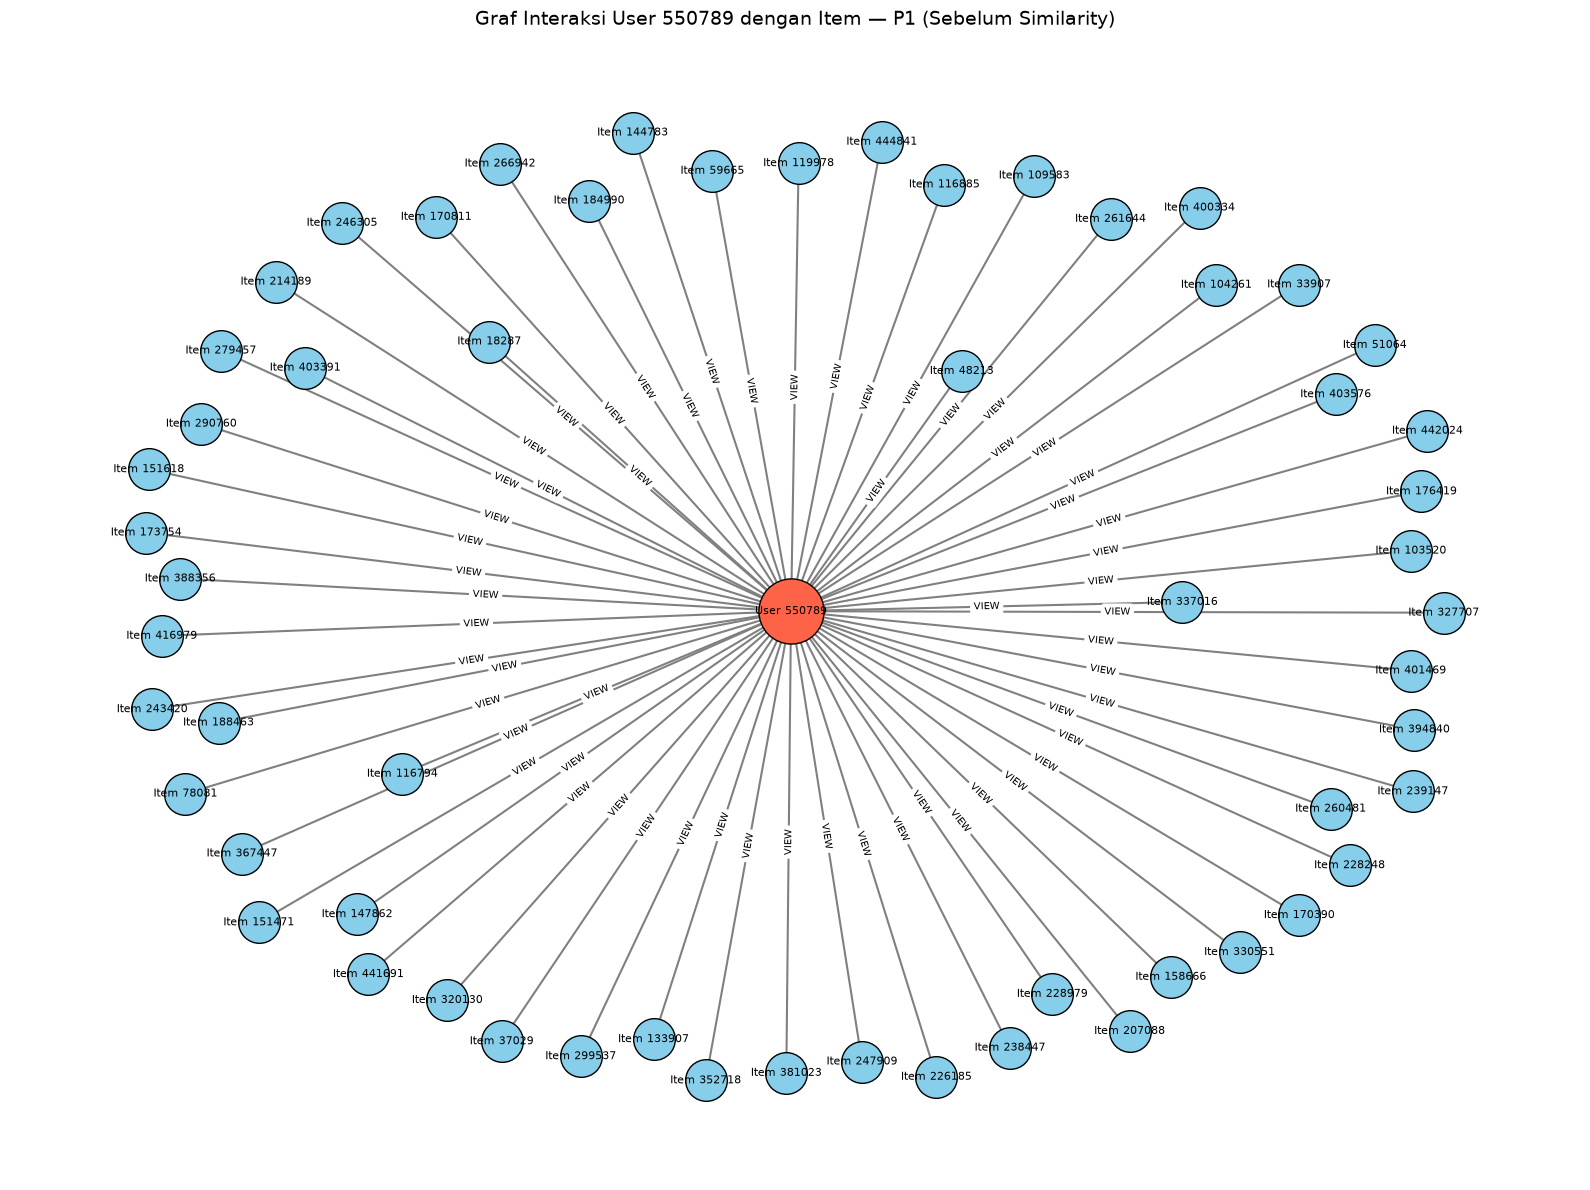

User acuan: 550789
Jumlah baris interaksi P1: 176
Jumlah item unik yang ditampilkan: 58
Jumlah node: 59
Jumlah edge: 58

Distribusi jenis interaksi yang ditampilkan:
event
VIEW    58
Name: count, dtype: int64


In [105]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ============================================================
# 2. KONFIGURASI USER ACUAN
# ============================================================
user_id = "550789"

# ============================================================
# 3. CYPHER: AMBIL INTERAKSI USER PADA P1
# ============================================================
QUERY_USER_GRAPH = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE v.visitorId = $user_id
  AND r.period = 'P1'
  AND type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
RETURN
    v.visitorId AS user_id,
    i.itemId AS item_id,
    type(r) AS event,
    r.timestamp AS timestamp
ORDER BY r.timestamp
"""

with driver.session() as session:
    result = session.run(
        QUERY_USER_GRAPH,
        user_id=user_id
    )
    interaction_df = pd.DataFrame(
        [record.data() for record in result]
    )

# Periksa hasil query
if interaction_df.empty:
    raise ValueError(
        f"Tidak ditemukan interaksi P1 untuk user {user_id}. "
        "Periksa tipe visitorId dan data periode."
    )

# ============================================================
# 4. BATASI MAKSIMAL 58 ITEM UNIK
# ============================================================
interaction_limited = (
    interaction_df
    .drop_duplicates(subset=["item_id"])
    .head(58)
)

# ============================================================
# 5. MEMBANGUN GRAF USER-ITEM
# ============================================================
G = nx.Graph()

user_node = f"User {user_id}"
G.add_node(user_node, node_type="user")

for _, row in interaction_limited.iterrows():
    item_node = f"Item {row['item_id']}"

    G.add_node(item_node, node_type="item")

    G.add_edge(
        user_node,
        item_node,
        relationship=row["event"]
    )

# ============================================================
# 6. VISUALISASI GRAF DI PYTHON
# ============================================================
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=1.2)

user_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "user"
]

item_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "item"
]

# Node user
nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_size=2200,
    node_color="tomato",
    edgecolors="black"
)

# Node item
nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_size=900,
    node_color="skyblue",
    edgecolors="black"
)

# Garis hubungan
nx.draw_networkx_edges(
    G, pos,
    edge_color="gray",
    width=1.5
)

# Label node
nx.draw_networkx_labels(
    G, pos,
    font_size=8
)

# Label jenis interaksi
edge_labels = nx.get_edge_attributes(G, "relationship")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7
)

plt.title(
    f"Graf Interaksi User {user_id} dengan Item — P1 "
    "(Sebelum Similarity)",
    fontsize=14
)

plt.axis("off")
plt.tight_layout()
plt.show()

# ============================================================
# 7. INFORMASI GRAF
# ============================================================
print("User acuan:", user_id)
print("Jumlah baris interaksi P1:", len(interaction_df))
print("Jumlah item unik yang ditampilkan:", len(interaction_limited))
print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())

print("\nDistribusi jenis interaksi yang ditampilkan:")
print(interaction_limited["event"].value_counts())

**Graf setelah similarity pada user acuan**

========== 5 USER DENGAN SIMILARITY TERTINGGI ==========


,reference_id,similar_id,similarity,rank
0,550789,143930,0.170103,1
1,550789,958890,0.136083,2
2,550789,917791,0.130437,3
3,550789,972009,0.125988,4
4,550789,1333313,0.125000,5


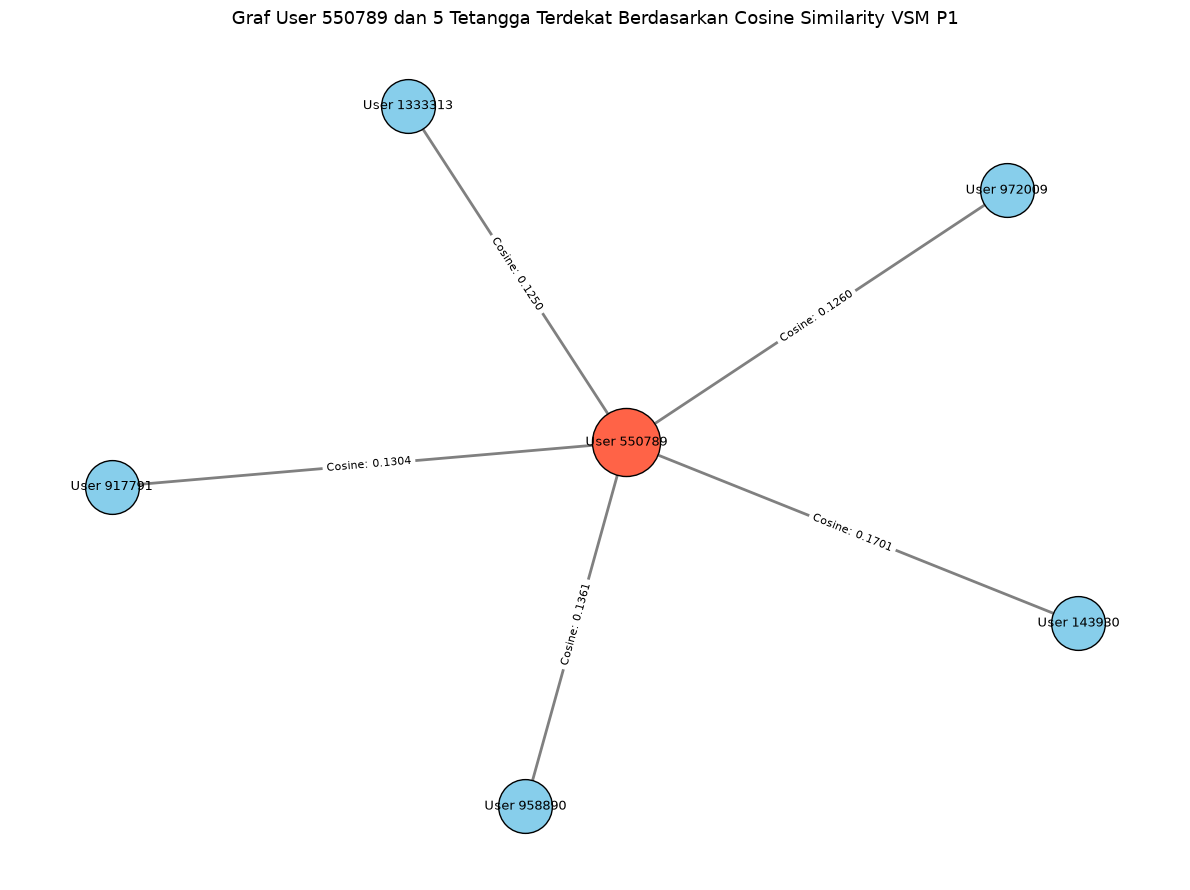

User acuan: 550789
Jumlah user tetangga: 5
Jumlah node: 6
Jumlah edge: 5


In [106]:

# ============================================================
# 1. IMPORT LIBRARY
# ============================================================
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ============================================================
# 2. KONFIGURASI USER ACUAN
# ============================================================
user_id = "550789"

# ============================================================
# 3. CYPHER: AMBIL 5 USER DENGAN SIMILARITY TERTINGGI
# ============================================================
QUERY_SIMILARITY_GRAPH = """
MATCH (a:Visitor)-[r:SIMILAR_TO]->(b:Visitor)
WHERE toString(a.visitorId) = $user_id
  AND r.cosine_similarity IS NOT NULL
  AND r.period = 'P1'
  AND r.method = 'VSM_COSINE'
RETURN
    toString(a.visitorId) AS reference_id,
    toString(b.visitorId) AS similar_id,
    toFloat(r.cosine_similarity) AS similarity,
    toInteger(r.rank) AS rank
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(
        QUERY_SIMILARITY_GRAPH,
        user_id=user_id
    )
    similarity_df = pd.DataFrame(
        [record.data() for record in result]
    )

if similarity_df.empty:
    raise ValueError(
        f"Tidak ditemukan relasi SIMILAR_TO dengan cosine_similarity "
        f"untuk user {user_id}. Pastikan user ini termasuk kandidat "
        f"yang similarity-nya sudah dihitung dan disimpan di Neo4j."
    )

print("========== 5 USER DENGAN SIMILARITY TERTINGGI ==========")
display(similarity_df)

# ============================================================
# 4. MEMBANGUN GRAF USER-USER
# ============================================================
G = nx.Graph()

reference_node = f"User {user_id}"
G.add_node(reference_node, node_type="reference")

for _, row in similarity_df.iterrows():
    similar_node = f"User {row['similar_id']}"

    G.add_node(similar_node, node_type="similar")
    G.add_edge(
        reference_node,
        similar_node,
        similarity=float(row["similarity"])
    )

# ============================================================
# 5. VISUALISASI GRAF DI PYTHON
# ============================================================
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5
)

reference_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "reference"
]

similar_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "similar"
]

# User acuan
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=reference_nodes,
    node_size=2400,
    node_color="tomato",
    edgecolors="black"
)

# Lima user terdekat
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=similar_nodes,
    node_size=1500,
    node_color="skyblue",
    edgecolors="black"
)

# Garis hubungan
nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    width=2
)

# Label user
nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

# Label cosine similarity pada setiap garis
edge_labels = {
    (u, v): f"Cosine: {data['similarity']:.4f}"
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    f"Graf User {user_id} dan 5 Tetangga Terdekat "
    "Berdasarkan Cosine Similarity VSM P1",
    fontsize=13
)

plt.axis("off")
plt.tight_layout()
plt.show()

# ============================================================
# 6. INFORMASI GRAF
# ============================================================
print("User acuan:", user_id)
print("Jumlah user tetangga:", len(similarity_df))
print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())


**JAWABAN NO.8** 
- Pada graf pertama, user acuan 550789 terhubung dengan 58 item yang diinteraksikan pada periode P1, sehingga terbentuk graf dengan maksimal 59 node dan 58 edge. Graf ini merepresentasikan riwayat interaksi user dengan item sebelum perhitungan similarity. 
- Pada graf kedua, setelah perhitungan cosine similarity berdasarkan VSM User P1, user acuan terhubung dengan lima user yang memiliki tingkat kemiripan tertinggi. 

Dengan demikian, graf pertama menggambarkan hubungan antara user dan item, sedangkan graf kedua menunjukkan hubungan kemiripan antaruser yang dapat dimanfaatkan untuk mendukung proses rekomendasi.

## **Analytics**

**Konfigurasi dan library**

In [107]:

import pandas as pd
import numpy as np
import math

# User acuan
user_id = "550789"

# Parameter rekomendasi
K = 5
N_DISPLAY = 3
N_EVAL = 5

print("User acuan:", user_id)
print("Jumlah tetangga KNN:", K)
print("Jumlah item yang ditampilkan:", N_DISPLAY)
print("Jumlah item untuk evaluasi:", N_EVAL)


User acuan: 550789
Jumlah tetangga KNN: 5
Jumlah item yang ditampilkan: 3
Jumlah item untuk evaluasi: 5


**Mengambil 5 tetangga terdekat**

Mengambil hasil similarity yang sudah tersimpan, mengubahnya menjadi jarak \(1-similarity), lalu memilih lima tetangga dengan jarak terkecil.

In [108]:

# ============================================================
# 1. KONFIGURASI
# ============================================================
user_id = "550789"
K = 5

# ============================================================
# 2. CYPHER: AMBIL K TETANGGA TERDEKAT
# ============================================================
QUERY_KNN = """
MATCH (u:Visitor)-[r:SIMILAR_TO]->(v:Visitor)
WHERE toString(u.visitorId) = $user_id
  AND r.cosine_similarity IS NOT NULL
  AND r.period = 'P1'
  AND r.method = 'VSM_COSINE'

WITH
    u,
    v,
    toFloat(r.cosine_similarity) AS similarity,
    1.0 - toFloat(r.cosine_similarity) AS distance

RETURN
    toString(u.visitorId) AS reference_id,
    toString(v.visitorId) AS neighbor_id,
    similarity,
    distance
ORDER BY distance ASC
LIMIT $k
"""

# ============================================================
# 3. EKSEKUSI QUERY NEO4J
# ============================================================
with driver.session() as session:
    result = session.run(
        QUERY_KNN,
        user_id=user_id,
        k=K
    )
    neighbors_df = pd.DataFrame(
        [record.data() for record in result]
    )

# ============================================================
# 4. VALIDASI DAN TAMPILKAN HASIL
# ============================================================
if neighbors_df.empty:
    raise ValueError(
        f"Tidak ditemukan relasi SIMILAR_TO dengan cosine_similarity "
        f"untuk user {user_id}. Pastikan user tersebut termasuk kandidat "
        "yang similarity-nya sudah dihitung dan disimpan di Neo4j."
    )

print(f"========== {K} TETANGGA TERDEKAT ==========")
print("User acuan:", user_id)
display(neighbors_df)


========== 5 TETANGGA TERDEKAT ==========
User acuan: 550789


,reference_id,neighbor_id,similarity,distance
0,550789,143930,0.170103,0.829897
1,550789,958890,0.136083,0.863917
2,550789,917791,0.130437,0.869563
3,550789,972009,0.125988,0.874012
4,550789,1333313,0.125000,0.875000


**Mengambil riwayat item milik tetangga**

Mengumpulkan item yang diinteraksikan oleh lima tetangga pada P1. Semua jenis interaksi berikut diperhitungkan: VIEW, ADDTOCART, dan TRANSACTION. Sistem rekomendasi memanfaatkan item yang disukai atau setidaknya pernah diinteraksikan oleh user yang mirip. Item dari tetangga akan menjadi kandidat rekomendasi.

In [110]:

# ============================================================
# 1. CYPHER: HITUNG RIWAYAT ITEM SETIAP TETANGGA
# ============================================================
QUERY_NEIGHBOR_ITEM_COUNT = """
UNWIND $neighbors AS neighbor

OPTIONAL MATCH (v:Visitor)-[r]->(i:Item)
WHERE toString(v.visitorId) = toString(neighbor.neighbor_id)
  AND r.period = 'P1'
  AND type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']

WITH
    neighbor,
    count(DISTINCT i.itemId) AS unique_item_count,
    count(r) AS interaction_count

RETURN
    toString(neighbor.neighbor_id) AS neighbor_id,
    toFloat(neighbor.similarity) AS similarity,
    unique_item_count,
    interaction_count
ORDER BY similarity DESC
"""

# ============================================================
# 2. SIAPKAN 5 TETANGGA
# ============================================================
neighbor_records = [
    {
        "neighbor_id": str(row["neighbor_id"]),
        "similarity": float(row["similarity"])
    }
    for _, row in neighbors_df.iterrows()
]

if not neighbor_records:
    raise ValueError(
        "neighbors_df kosong. Pastikan 5 tetangga sudah diperoleh."
    )

# ============================================================
# 3. EKSEKUSI QUERY
# ============================================================
with driver.session() as session:
    result = session.run(
        QUERY_NEIGHBOR_ITEM_COUNT,
        neighbors=neighbor_records
    )
    neighbor_count_df = pd.DataFrame(
        [record.data() for record in result]
    )

# ============================================================
# 4. TAMPILKAN JUMLAH RIWAYAT ITEM PER TETANGGA
# ============================================================
print("========== JUMLAH RIWAYAT ITEM PER TETANGGA ==========")
display(neighbor_count_df)

print("\nJumlah tetangga yang diperiksa:", len(neighbor_records))
print("Jumlah tetangga pada hasil:", neighbor_count_df["neighbor_id"].nunique())
print(
    "Total item unik lintas tetangga:",
    neighbor_count_df["unique_item_count"].sum()
)


========== JUMLAH RIWAYAT ITEM PER TETANGGA ==========


,neighbor_id,similarity,unique_item_count,interaction_count
0,143930,0.170103,6,8
1,958890,0.136083,6,6
2,917791,0.130437,20,28
3,972009,0.125988,7,7
4,1333313,0.125000,16,24



Jumlah tetangga yang diperiksa: 5
Jumlah tetangga pada hasil: 5
Total item unik lintas tetangga: 55


**Mengambil riwayat item acuan pada P1**

mengetahui item yang sudah pernah dilihat atau diinteraksikan user acuan. Item ini dikeluarkan dari kandidat rekomendasi agar sistem tidak menyarankan item yang sama kembali.

In [111]:
# ============================================================
# CELL 1: RIWAYAT ITEM USER ACUAN PADA P1
# ============================================================

QUERY_REFERENCE_HISTORY = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE toString(u.visitorId) = $user_id
  AND r.period = 'P1'
  AND type(r) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
RETURN DISTINCT toString(i.itemId) AS item_id
"""

with driver.session() as session:
    result = session.run(
        QUERY_REFERENCE_HISTORY,
        user_id=str(user_id)
    )
    reference_history_df = pd.DataFrame(
        [record.data() for record in result]
    )

seen_items = set(
    reference_history_df["item_id"].astype(str)
    if not reference_history_df.empty
    else []
)

print("User acuan:", user_id)
print("Jumlah item unik yang sudah diinteraksikan pada P1:", len(seen_items))

User acuan: 550789
Jumlah item unik yang sudah diinteraksikan pada P1: 144


**Membuat skor rekomendasi dari 5 tetangga**

Skor menggunakan jumlah berbobot:
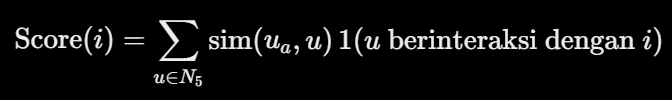

**Mengambil 3 item yang direkomendasikan untuk diiklankan**

In [113]:
# ============================================================
# CELL 3: PILIH 3 ITEM UNTUK DIiklankan
# ============================================================

N_AD_ITEMS = 3

advertised_items_df = recommendation_scores.head(
    N_AD_ITEMS
).copy()

advertised_items_df = advertised_items_df.rename(
    columns={
        "item_id": "advertised_item_id"
    }
)

print(f"========== {N_AD_ITEMS} ITEM YANG DIREKOMENDASIKAN ==========")
print("User acuan:", user_id)

display(
    advertised_items_df[
        [
            "rank",
            "advertised_item_id",
            "recommendation_score",
            "supporting_neighbors"
        ]
    ]
)

========== 3 ITEM YANG DIREKOMENDASIKAN ==========
User acuan: 550789


,rank,advertised_item_id,recommendation_score,supporting_neighbors
0,1,359542,0.170103,1
1,2,134576,0.136083,1
2,3,66921,0.136083,1


**JAWABAN 2.2 A** Didapatkan 3 item untuk diiklankan dengan k=5 seperti hasil diatas

**Mengambil ground truth user acuan dari P2**

In [114]:
# ============================================================
# CELL 4: GROUND TRUTH P2
# ============================================================

QUERY_GROUND_TRUTH = """
MATCH (u:Visitor)-[r2]->(i:Item)
WHERE toString(u.visitorId) = $user_id
  AND r2.period = 'P2'
  AND type(r2) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']

WITH u, i
WHERE NOT EXISTS {
    MATCH (u)-[r1]->(i)
    WHERE r1.period = 'P1'
      AND type(r1) IN ['VIEW', 'ADDTOCART', 'TRANSACTION']
}

RETURN DISTINCT toString(i.itemId) AS item_id
"""

with driver.session() as session:
    result = session.run(
        QUERY_GROUND_TRUTH,
        user_id=str(user_id)
    )
    ground_truth_df = pd.DataFrame(
        [record.data() for record in result]
    )

ground_truth_items = set(
    ground_truth_df["item_id"].astype(str)
    if not ground_truth_df.empty
    else []
)

print("Jumlah item ground truth P2:", len(ground_truth_items))
print("Contoh item ground truth:")
display(ground_truth_df.head(10))

Jumlah item ground truth P2: 5
Contoh item ground truth:


,item_id
0,86497
1,243110
2,193242
3,63651
4,173766


**Evaluasi Hit@5 dan NDCG@5**

In [115]:
# ============================================================
# CELL 5: EVALUASI HIT@5 DAN NDCG@5
# ============================================================

import numpy as np

EVAL_K = 5

# Daftar ranking item untuk evaluasi, bukan hanya 3 item iklan
top_k_items = (
    recommendation_scores
    .head(EVAL_K)["item_id"]
    .astype(str)
    .tolist()
)

# Relevansi biner: 1 jika item terdapat pada ground truth P2
relevance = np.array(
    [1 if item in ground_truth_items else 0 for item in top_k_items],
    dtype=float
)

# Hit@5: apakah setidaknya satu item relevan muncul dalam top-5?
hit_at_5 = float(np.sum(relevance) > 0)

# DCG@5 dengan gain biner dan diskon logaritmik
discounts = np.log2(np.arange(2, len(relevance) + 2))
dcg_at_5 = float(np.sum(relevance / discounts))

# IDCG@5: DCG ideal berdasarkan jumlah item relevan yang tersedia
ideal_relevance = np.ones(
    min(len(ground_truth_items), len(top_k_items)),
    dtype=float
)
ideal_discounts = np.log2(
    np.arange(2, len(ideal_relevance) + 2)
)
idcg_at_5 = float(
    np.sum(ideal_relevance / ideal_discounts)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

evaluation_df = pd.DataFrame([{
    "user_id": str(user_id),
    "KNN_neighbors": len(neighbors_df),
    "evaluation_cutoff": EVAL_K,
    "recommended_items_evaluated": len(top_k_items),
    "ground_truth_count": len(ground_truth_items),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

print("========== HASIL EVALUASI ==========")
display(evaluation_df)

print("Item top-5 yang dievaluasi:")
display(
    recommendation_scores.head(EVAL_K)[
        ["rank", "item_id", "recommendation_score"]
    ]
)

========== HASIL EVALUASI ==========


,user_id,KNN_neighbors,evaluation_cutoff,recommended_items_evaluated,ground_truth_count,Hit@5,NDCG@5
0,550789,5,5,5,5,0.0,0.0


Item top-5 yang dievaluasi:


,rank,item_id,recommendation_score
0,1,359542,0.170103
1,2,134576,0.136083
2,3,66921,0.136083
3,4,139296,0.130437
4,5,262982,0.130437


**JAWABAN 2.2.2**
Hasil evaluasi KNN menunjukkan bahwa sistem menghasilkan lima rekomendasi item untuk user acuan 550789, yaitu 359542, 134576, 66921, 139296, dan 262982. Namun, tidak ada item rekomendasi yang termasuk dalam daftar ground truth pada data pengujian (testing), sehingga seluruh nilai relevansi pada lima peringkat adalah 0, dengan nilai Hit@5 = 0 dan NDCG@5 = 0,0. Nilai rendah wajar karena rata-rata user hanya punya 1,51 item, interaksi sangat jarang, dan P2 adalah periode berbeda dari P1; nilai nol pada satu user tidak mewakili kualitas model secara keseluruhan.

In [ ]:
driver.close()